In [103]:
from SyntheticData.simulate_data import simulate_competing_risks

import pandas as pd
import numpy as np

import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedKFold
import random
import os
from sksurv.metrics import integrated_brier_score
from pycox.evaluation import EvalSurv
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from sksurv.nonparametric import kaplan_meier_estimator
from typing import Optional, Tuple
from pathlib import Path
from lifelines import KaplanMeierFitter


# Data Used

In [104]:
df_synthetic, true_beta_event1, true_beta_event2 = simulate_competing_risks(n_samples=15000, seed=42,baseline_hazard_event1=0.01, baseline_hazard_event2=0.05,censoring_rate=0.01)

df_synthetic.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,time,event,true_lp_event1,true_lp_event2
0,0.304717,-1.039984,0.750451,0.940565,-1.951035,-1.302180,0.0,0.0,0.0,0.0,0.0,1.0,58.593640,2,0.003896,-1.011819
1,0.127840,-0.316243,-0.016801,-0.853044,0.879398,0.777792,0.0,0.0,0.0,1.0,1.0,0.0,10.612771,0,1.570361,0.420315
2,0.066031,1.127241,0.467509,-0.859292,0.368751,-0.958883,1.0,1.0,1.0,0.0,1.0,1.0,0.332888,2,0.113161,3.523734
3,0.878450,-0.049926,-0.184862,-0.680930,1.222541,-0.154529,0.0,1.0,0.0,1.0,0.0,0.0,1.147042,1,0.396907,-0.200975
4,-0.428328,-0.352134,0.532309,0.365444,0.412733,0.430821,1.0,1.0,1.0,1.0,1.0,1.0,4.869356,2,0.395845,1.020305


In [105]:
print(df_synthetic['event'].value_counts())

event
2    9193
1    3626
0    2181
Name: count, dtype: int64


In [106]:
print(df_synthetic['true_lp_event1'].var(), df_synthetic['true_lp_event2'].var())

4.611702690062645 3.3710173717594856


# Profiler

In [107]:
import psutil
import time
import threading
import pandas as pd
import matplotlib.pyplot as plt

def monitor_resources(interval, stats, stop_event):
    process = psutil.Process()
    while not stop_event.is_set():
        cpu = process.cpu_percent()
        mem = process.memory_info().rss / (1024 * 1024)  # in MB
        timestamp = time.time()
        stats.append({'time': timestamp, 'cpu': cpu, 'memory': mem})
        time.sleep(interval)

def profile_function(func, *args, interval=0.5, **kwargs):
    stats = []
    stop_event = threading.Event()

    monitor_thread = threading.Thread(target=monitor_resources, args=(interval, stats, stop_event))
    
    start_time = time.time()
    monitor_thread.start()

    result = func(*args, **kwargs)

    stop_event.set()
    monitor_thread.join()
    end_time = time.time()

    duration = end_time - start_time
    print(f"Function took {duration:.2f} seconds")

    return result, pd.DataFrame(stats), duration


# Model

In [108]:
def km_survival_left_limit(kmf, times):
    times = np.asarray(times, dtype=float)
    curve = kmf.survival_function_.iloc[:, 0]
    grid = curve.index.to_numpy(dtype=float)
    values = curve.to_numpy(dtype=float)
    pos = np.searchsorted(grid, times, side="left") - 1
    out = np.ones_like(times)
    valid = pos >= 0
    out[valid] = values[pos[valid]]
    return out

In [109]:
class FeatureNet(nn.Module):

    def __init__(self, hidden_dim: int, num_hidden_layers: int, dropout: float, output_dim: int):
        super().__init__()
        layers = []
        in_dim = 1
        
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            # layers.append(nn.Tanh())
            layers.append(nn.SiLU())
            layers.append(nn.Dropout(dropout))
            in_dim = hidden_dim
            
        # 1. Disable bias on final layer so baseline risk belongs to global model bias
        layers.append(nn.Linear(hidden_dim, output_dim, bias=False))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        out = self.net(x)   # shape: [batch_size, output_dim]
        
        # 2. Enforce zero-mean constraint across the batch dimension
        if self.training and out.shape[0] > 1:
            return out - out.mean(dim=0, keepdim=True)
        return out


class CRISPNAMBase(nn.Module):

    def __init__(
        self,
        input_dim: int,
        hidden_dim: int = 32,
        num_hidden_layers: int = 5,
        dropout: float = 0.2,
        output_dim: int = 1,   # Base model predicts 1 target cause at a time
    ):
        super().__init__()

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim

        # Instantiate a standalone FeatureNet for each input dimension
        self.feature_nets = nn.ModuleList([
            FeatureNet(hidden_dim, num_hidden_layers, dropout, output_dim) for _ in range(input_dim)
        ])
        
        # Global bias term for the additive model
        self.bias = nn.Parameter(torch.zeros(1))

        self._reset_parameters()

    def _reset_parameters(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor, return_embedding: bool = False) -> torch.Tensor | Tuple[torch.Tensor, torch.Tensor]:

        feature_outputs = []
        
        # Pass each individual feature through its dedicated FeatureNet
        for i in range(self.input_dim):
            # Extract single feature, reshape to [batch_size, 1]
            feat = x[:, i].unsqueeze(1)
            out = self.feature_nets[i](feat) 
            feature_outputs.append(out)
            
        # Stack into shape: [batch_size, input_dim, 1]
        stacked_outputs = torch.stack(feature_outputs, dim=1)
        
        # Additive aggregation: Sum across the feature dimension
        # Shape becomes [batch_size, 1]
        risk_score = stacked_outputs.sum(dim=1) + self.bias
        
        if return_embedding:
            # Return the final score and the matrix of individual feature contributions
            return risk_score, stacked_outputs
        return risk_score

    
    def compute_baseline_subdistribution_hazards(
            self, train_loader, kmf_censor, cause=1, device="cuda", eps=1e-12
        ):
            """Weighted Breslow-type baseline subdistribution hazard for target cause.

            Assumes marginal independent censoring and a censoring Kaplan--Meier
            estimator fitted on the TRAINING FOLD, with event_observed=(events==0).
            Uses full TRAINING-FOLD risk sets when calibrating the baseline; model
            training can independently use mini-batch risk-set approximations.
            """
            if kmf_censor is None:
                raise ValueError("Pass training-fold censoring KM as kmf_censor.")

            self.eval()
            times_list, events_list, scores_list = [], [], []
            with torch.no_grad():
                for batch in train_loader:
                    batch_x, batch_t, batch_e = batch[:3]

                    scores = self(batch_x.to(device)).reshape(-1)
                    times_list.append(batch_t.detach().cpu().numpy())
                    events_list.append(batch_e.detach().cpu().numpy())
                    scores_list.append(scores.detach().cpu().numpy())

            if not times_list:
                raise ValueError("Empty train_loader.")

            times = np.concatenate(times_list).astype(np.float64)
            events = np.concatenate(events_list).astype(np.int64)
            eta = np.concatenate(scores_list).astype(np.float64)

            event_times = np.unique(times[events == cause])
            if len(event_times) == 0:
                return np.empty(0, dtype=np.float64), np.empty(0, dtype=np.float64)

            g_obs = km_survival_left_limit(kmf_censor, times)
            g_evt = km_survival_left_limit(kmf_censor, event_times)
            increments = np.empty(len(event_times), dtype=np.float64)

            for ii, (t, g_t) in enumerate(zip(event_times, g_evt)):
                if not np.isfinite(g_t) or g_t <= eps:
                    raise ValueError(f"Censoring survival nonpositive at event time {t}.")

                active = times >= t
                prior_competing = (times < t) & (events != 0) & (events != cause)
                included = active | prior_competing

                # In the normalized FG formulation, active subjects have weight 1.
                # Prior competing-event subjects have weight G_hat(t-)/G_hat(T_j-).
                if np.any(g_obs[prior_competing] <= eps):
                    raise ValueError("Censoring survival nonpositive at prior competing event.")
                log_fg = np.zeros(len(times), dtype=np.float64)
                log_fg[prior_competing] = (
                    np.log(g_t) - np.log(g_obs[prior_competing])
                )

                log_denominator = np.logaddexp.reduce(eta[included] + log_fg[included])
                failures = np.count_nonzero((times == t) & (events == cause))
                increments[ii] = failures * np.exp(-log_denominator)

            # Jumps occur ONLY at target-cause event times.
            return event_times, np.cumsum(increments)

    

    @staticmethod
    def evaluate_step_cumulative_baseline(
        query_times,
        baseline_times,
        baseline_cum_hazard
    ):
        """Right-continuous step interpolation of cumulative baseline hazard."""

        query_times = np.asarray(query_times, dtype=np.float64)
        base_times = np.asarray(baseline_times, dtype=np.float64)
        cum_hazard = np.asarray(baseline_cum_hazard, dtype=np.float64)

        result = np.zeros_like(query_times, dtype=np.float64)

        if len(base_times):
            positions = np.searchsorted(
                base_times,
                query_times,
                side="right"
            ) - 1

            valid = positions >= 0
            result[valid] = cum_hazard[positions[valid]]

        return result


        
    def predict_survival(
        self,
        x: torch.Tensor,
        times: np.ndarray,
        baseline_times=None,
        baseline_cum_hazard=None
    ) -> torch.Tensor:

        log_risk = self.forward(x).reshape(-1, 1)
        hazard_ratio = torch.exp(log_risk)

        if baseline_times is None or baseline_cum_hazard is None:
            raise ValueError(
                "A fitted Fine-Gray cumulative baseline hazard is required."
            )

        # Correct step-function evaluation instead of np.interp()
        step_hazard = self.evaluate_step_cumulative_baseline(
            times,
            baseline_times,
            baseline_cum_hazard
        )

        hazard_tensor = torch.as_tensor(
            step_hazard,
            dtype=log_risk.dtype,
            device=x.device
        ).reshape(1, -1)

        # Fine-Gray cumulative incidence function
        cif = 1.0 - torch.exp(-hazard_ratio * hazard_tensor)

        # Complement of cause-specific cumulative incidence
        survival_probs = 1.0 - cif

        return torch.clamp(survival_probs, 0.0, 1.0)


In [110]:
import torch
import torch.nn as nn
import numpy as np

class RiskSetSampling(nn.Module):

    def __init__( 
        self, 
        method: str = "full", 
        cause: int = 1, 
        censor_code: int = 0, 
        n_controls: int = 5,           # For NCC / Entropy
        subcohort_frac: float = 0.2,   # For SCC
        tau: float = 1.0,              # Temperature for Entropy sampling
        compression_rate: float = 0.1, # Target retention rate for Entropy sampling
        eps: float = 1e-8
    ):
        super().__init__()
        assert method in ["full", "scc", "ncc", "entropy"], f"Unknown method: {method}"
        self.method = method
        self.cause = cause
        self.censor_code = censor_code
        self.n_controls = n_controls
        self.subcohort_frac = subcohort_frac
        self.tau = tau
        self.compression_rate = compression_rate
        self.eps = eps
        self.current_compression_ratio = -1.0
        self.register_buffer(
            "_scc_subcohort",
            torch.empty(0, dtype=torch.bool),
            persistent=False
        )

    def build_fg_risk_mask(self, times: torch.Tensor, events: torch.Tensor) -> torch.Tensor:
        """Constructs the base Fine-Gray subdistribution risk set mask [E, N]."""
        event_idx = torch.where(events == self.cause)[0]
        if len(event_idx) == 0:
            return None, None
            
        t_i = times[event_idx].unsqueeze(1)
        t_j = times.unsqueeze(0)
        e_j = events.unsqueeze(0)

        at_risk = (t_j >= t_i)
        competing_prior = (t_j < t_i) & (e_j != self.censor_code) & (e_j != self.cause)
        risk_mask = at_risk | competing_prior
        return risk_mask, event_idx

    def initialize_scc(self, n_train, device):
        if self.method == "scc":
            self._scc_subcohort = (
                torch.rand(n_train, device=device)
                < self.subcohort_frac
            )

    def forward(self, times: torch.Tensor, events: torch.Tensor, risk_scores: torch.Tensor = None, ids: torch.Tensor = None):
        """
        Returns:
            sampled_mask: [E, N] boolean tensor of sampled risk sets.
            pi_matrix: [E, N] tensor of inclusion probabilities.
        """
        device = times.device
        N = len(times)
        
        base_mask, event_idx = self.build_fg_risk_mask(times, events)
        if base_mask is None:
            return None, None
            
        E = len(event_idx)


        if self.method == "full":
            pi_matrix = torch.ones((E, N), device=device)
            return base_mask, pi_matrix


        # elif self.method == "scc":
        #     # Randomly select subcohort at baseline
        #     subcohort_mask = (torch.rand(N, device=device) < self.subcohort_frac)
            
        #     # Mask = (j in subcohort) OR (j is the target case i)
        #     sampled_mask = base_mask & subcohort_mask.unsqueeze(0)
            
        #     # Cases are always included (mask diagonals basically, but broadcasted)
        #     # Actually, Fine-Gray cases inside the risk set are strictly preserved
        #     for row, e_id in enumerate(event_idx):
        #         sampled_mask[row, e_id] = True
            
        #     # pi = subcohort_frac for controls, 1.0 for cases
        #     pi_matrix = torch.full((E, N), self.subcohort_frac, device=device)
        #     for row, e_id in enumerate(event_idx):
        #         pi_matrix[row, e_id] = 1.0
                
        #     return sampled_mask, pi_matrix



        
        elif self.method == "scc":
        # Static case-cohort sampling.
        # One baseline subcohort is reused across all mini-batches
        # and epochs within the training fold.

            if ids is None:
                raise ValueError("SCC requires stable observation IDs.")

            if self._scc_subcohort.numel() == 0:
                raise RuntimeError(
                    "Initialize SCC once before training."
                )

            # Retrieve baseline subcohort membership.
            # IDs only track membership after DataLoader shuffling.
            ids = ids.long().to(self._scc_subcohort.device)
            subcohort_mask = self._scc_subcohort[ids].to(device)

            # Start with eligible members of the fixed subcohort.
            sampled_mask = (
                base_mask & subcohort_mask.unsqueeze(0)
            )

            # Always include the CURRENT event case.
            # Do not automatically include other future cases.
            rows = torch.arange(E, device=device)
            sampled_mask[rows, event_idx] = True

            # Subcohort controls have inclusion probability alpha.
            pi_matrix = torch.full(
                (E, N),
                self.subcohort_frac,
                dtype=torch.float32,
                device=device
            )

            # The current event case is included with probability 1.
            pi_matrix[rows, event_idx] = 1.0

            # Track retained risk-set entries.
            total_possible = base_mask.sum().float()
            total_kept = sampled_mask.sum().float()

            self.current_compression_ratio = (
                total_kept / (total_possible + self.eps)
            ).item()

            return sampled_mask, pi_matrix

        elif self.method == "ncc":
            sampled_mask = torch.zeros_like(base_mask, dtype=torch.bool, device=device)
            pi_matrix = torch.ones_like(base_mask, dtype=torch.float, device=device)

            for row, e_id in enumerate(event_idx):
                # Valid controls are those in risk set, excluding the case itself
                valid_controls = base_mask[row].clone()
                valid_controls[e_id] = False
                control_indices = torch.where(valid_controls)[0]
                
                num_avail = len(control_indices)
                
                # Case is always sampled with pi=1.0
                sampled_mask[row, e_id] = True
                
                if num_avail > 0:
                    m_actual = min(self.n_controls, num_avail)
                    pi_val = m_actual / num_avail
                    
                    # Randomly sample m controls
                    perm = torch.randperm(num_avail, device=device)[:m_actual]
                    sampled_ctrls = control_indices[perm]
                    
                    sampled_mask[row, sampled_ctrls] = True
                    pi_matrix[row, valid_controls] = pi_val # All valid controls had this pi
                    
            return sampled_mask, pi_matrix

        elif self.method == SamplerType.ENTROPY:
            assert risk_scores is not None, "Entropy sampling requires model risk_scores."
            

            probs = torch.sigmoid(risk_scores)
            entropy = -probs * torch.log(probs + self.eps) - (1 - probs) * torch.log(1 - probs + self.eps)
            max_entropy = torch.log(torch.tensor(2.0, device=device))
            entropy_norm = entropy / max_entropy
            
            compression_rate = self.compression_rate


            # base_mask is [E, N] (Events x All Patients)
            valid_controls = base_mask.clone()
            
            # The case cannot be its own control, so we set the diagonal intersection to False
            # event_idx maps the E rows back to their original index in the N-length batch
            valid_controls[torch.arange(E, device=device), event_idx] = False
            

            # We apply temperature here
            weights_1d = torch.exp(entropy_norm / self.tau)
            weights_2d = weights_1d.unsqueeze(0).expand(E, N)
            
            # Zero out weights for subjects not in the risk set
            masked_weights = weights_2d * valid_controls
            

            # Sum of weights divided by number of valid controls
            num_avail = valid_controls.sum(dim=1, keepdim=True).float() + self.eps
            mean_weights = masked_weights.sum(dim=1, keepdim=True) / num_avail
            

            pi_vals_2d = torch.clamp((masked_weights / (mean_weights + self.eps)) * compression_rate, min=self.eps, max=1.0)
            

            keep_bool_2d = torch.bernoulli(pi_vals_2d).bool()
            
            # The final sampled mask keeps the active controls AND the target case
            sampled_mask = (valid_controls & keep_bool_2d)
            sampled_mask[torch.arange(E, device=device), event_idx] = True
            
            # The Pi matrix needs to record the pi_val for the kept controls, 
            # and 1.0 for the case. 
            pi_matrix = torch.ones_like(base_mask, dtype=torch.float, device=device)
            # Only update pi for valid controls (the case stays at 1.0, invalid controls don't matter)
            pi_matrix = torch.where(valid_controls, pi_vals_2d, pi_matrix)

            # Track compression
            if base_mask is not None:
                total_possible = base_mask.sum().float()
                total_kept = sampled_mask.sum().float()
                self.current_compression_ratio = (total_kept / (total_possible + self.eps)).item()

            return sampled_mask, pi_matrix

In [111]:
# import torch
# import torch.nn as nn
# from typing import Optional

# class SamplingIPCWFineGrayLoss(nn.Module):

#     def __init__(
#         self, 
#         cause: int = 1, 
#         censor_code: int = 0, 
#         max_weight: float = 50.0,
#         reduction: str = "mean",
#         eps: float = 1e-8
#     ):
#         super().__init__()
#         self.cause = cause
#         self.censor_code = censor_code
#         self.max_weight = max_weight
#         self.reduction = reduction
#         self.eps = eps

#     def forward(
#         self, 
#         risk_scores: torch.Tensor, 
#         times: torch.Tensor, 
#         events: torch.Tensor, 
#         pi: Optional[torch.Tensor] = None,
#         custom_risk_mask: Optional[torch.Tensor] = None,
#         g_hat: Optional[torch.Tensor] = None
#     ) -> torch.Tensor:
        
#         if risk_scores.dim() == 2:
#             risk_scores = risk_scores.squeeze(-1)
        
#         device = risk_scores.device
#         N = len(times)

#         # -------------------------------------------------------------
#         # 1. Target Event Identification (i: Delta_i = k)
#         # -------------------------------------------------------------
#         event_idx = torch.where(events == self.cause)[0]
#         E = len(event_idx)
        
#         if E == 0:
#             return torch.tensor(0.0, device=device, requires_grad=True)

#         # -------------------------------------------------------------
#         # 2. Define or Override Risk Set R*(T_i)
#         # -------------------------------------------------------------
#         if custom_risk_mask is not None:
#             # --- USE THE MASK FROM THE SAMPLER ---
#             risk_mask = custom_risk_mask
#         else:
#             # --- BUILD DEFAULT FULL RISK SET ---
#             t_i = times[event_idx].unsqueeze(1) 
#             t_j = times.unsqueeze(0)            
#             e_j = events.unsqueeze(0)           

#             at_risk = (t_j >= t_i)
#             competing_prior = (t_j < t_i) & (e_j != self.censor_code) & (e_j != self.cause)
#             risk_mask = at_risk | competing_prior  # Shape: (E, N)

#         # -------------------------------------------------------------
#         # 3. Compute 2D Subject Weights: w_{ij} = w_{ij}^{stab} * w_j^{cens}
#         # -------------------------------------------------------------
#         w_cens = 1.0 / (g_hat + self.eps) # Shape: (N,)
        
#         if pi is not None:
#             # Get mean sampling rate only for subjects actually in the active risk sets
#             p_s = torch.mean(pi[risk_mask]).detach()
#             w_stab = p_s / (pi + self.eps)               # Shape: (E, N)
            
#             # Combine 2D IPW weights with 1D IPCW weights
#             w_ij = w_stab * w_cens.unsqueeze(0)          # Shape: (E, N)
#         else:
#             w_ij = w_cens.unsqueeze(0).expand(E, N)      # Shape: (E, N)

#         w_ij = torch.clamp(w_ij, max=self.max_weight)

#         # -------------------------------------------------------------
#         # 4. Compute Log Denominator: log sum_{j in R*(T_i)} w_{ij} * exp(eta_j)
#         # -------------------------------------------------------------
#         scores_j = risk_scores.unsqueeze(0)              # Shape: (1, N)
#         log_w_ij = torch.log(w_ij + self.eps)            # Shape: (E, N)
#         logits_ij = scores_j + log_w_ij                  # Shape: (E, N)

#         # Mask subjects outside the sampler's risk set
#         masked_logits = torch.where(
#             risk_mask, 
#             logits_ij, 
#             torch.tensor(-1e9, device=device)
#         )

#         log_denom = torch.logsumexp(masked_logits, dim=1) # Shape: (E,)

#         # -------------------------------------------------------------
#         # 5. Compute Final Loss: - sum_{i: Delta_i = k} w_i [ eta_i - log_denom ]
#         # -------------------------------------------------------------
#         eta_i = risk_scores[event_idx]
        
#         # The outer weight w_i is the weight of the target case at their own event time
#         # This extracts w_ij where row is the event and col is the event's original index
#         w_i = w_ij[torch.arange(E, device=device), event_idx]
        
#         individual_terms = eta_i - log_denom
#         weighted_loss = - (w_i * individual_terms)

#         if self.reduction == "sum":
#             return torch.sum(weighted_loss)
#         elif self.reduction == "mean":
#             return torch.sum(weighted_loss) / (torch.sum(w_i) + self.eps)
#         else:
#             return torch.mean(weighted_loss)

In [112]:

import torch
import torch.nn as nn
from typing import Optional


class SamplingIPCWFineGrayLoss(nn.Module):
    """Sampling-aware mini-batch Fine-Gray negative log-partial likelihood.

    g_hat[j] must be G_hat(T_j-) from the training-fold
    censoring Kaplan-Meier estimator.
    """

    def __init__(
        self,
        cause: int = 1,
        censor_code: int = 0,
        max_weight: Optional[float] = None,
        reduction: str = "mean",
        eps: float = 1e-8
    ):
        super().__init__()

        if max_weight is not None:
            raise ValueError(
                "Upper weight clipping is disabled in this reference loss."
            )

        if reduction not in ("mean", "sum", "none"):
            raise ValueError("Invalid reduction.")

        self.cause = cause
        self.censor_code = censor_code
        self.reduction = reduction
        self.eps = eps

    def forward(
        self,
        risk_scores: torch.Tensor,
        times: torch.Tensor,
        events: torch.Tensor,
        pi: Optional[torch.Tensor] = None,
        custom_risk_mask: Optional[torch.Tensor] = None,
        g_hat: Optional[torch.Tensor] = None
    ) -> torch.Tensor:

        eta = risk_scores.reshape(-1)
        N = times.numel()

        if eta.numel() != N or events.numel() != N:
            raise ValueError(
                "Times, events and risk scores must have equal lengths."
            )

        # ---------------------------------------------------------
        # 1. Identify observed target-cause events
        # ---------------------------------------------------------
        event_idx = torch.where(events == self.cause)[0]
        E = event_idx.numel()

        if E == 0:
            return eta.sum() * 0.0

        if g_hat is None:
            raise ValueError(
                "Provide G_hat(T_j-) from the training-fold KM estimator."
            )

        g = torch.as_tensor(
            g_hat, device=eta.device, dtype=eta.dtype
        ).reshape(-1).detach()

        if g.numel() != N or not bool(
            ((g >= 0) & (g <= 1) & torch.isfinite(g)).all()
        ):
            raise ValueError("Invalid censoring survival probabilities.")

        # ---------------------------------------------------------
        # 2. Construct the complete mini-batch Fine-Gray risk set
        # ---------------------------------------------------------
        t_i = times[event_idx].unsqueeze(1)  # (E, 1)
        t_j = times.unsqueeze(0)             # (1, N)
        e_j = events.unsqueeze(0)            # (1, N)

        active = (t_j >= t_i)

        prior_competing = (
            (t_j < t_i)
            & (e_j != self.censor_code)
            & (e_j != self.cause)
        )

        eligible = active | prior_competing

        if custom_risk_mask is None:
            selected = eligible
        else:
            selected = custom_risk_mask.to(
                device=eta.device, dtype=torch.bool
            )

            if selected.shape != (E, N):
                raise ValueError("Invalid sampled risk-set dimensions.")

            if bool((selected & ~eligible).any()):
                raise ValueError(
                    "Sampled risk set contains ineligible observations."
                )

        rows = torch.arange(E, device=eta.device)

        if not bool(selected[rows, event_idx].all()):
            raise ValueError("The target event case must be retained.")

        # ---------------------------------------------------------
        # 3. Correct Fine-Gray censoring weights
        #
        # Active:            w_FG = 1
        # Prior competing:   w_FG = G(T_i-) / G(T_j-)
        # Otherwise:         excluded
        # ---------------------------------------------------------
        if bool((g[event_idx] <= self.eps).any()):
            raise ValueError(
                "Censoring survival is zero at a target event time."
            )

        g_j = g.unsqueeze(0).expand(E, N)

        if bool((g_j[selected & prior_competing] <= self.eps).any()):
            raise ValueError(
                "Censoring survival is zero at a prior competing event."
            )

        log_g = torch.log(g.clamp_min(self.eps))

        log_fg = torch.where(
            active,
            torch.zeros((E, N), device=eta.device, dtype=eta.dtype),
            torch.where(
                prior_competing,
                log_g[event_idx].unsqueeze(1) - log_g.unsqueeze(0),
                torch.full(
                    (E, N), -torch.inf,
                    device=eta.device, dtype=eta.dtype
                )
            )
        )

        # ---------------------------------------------------------
        # 4. Sampling IPW: 1 / pi_ij
        # ---------------------------------------------------------
        if pi is None:
            if not torch.equal(selected, eligible):
                raise ValueError(
                    "Sampling a subset requires inclusion probabilities."
                )

            probs = torch.ones(
                (E, N), device=eta.device, dtype=eta.dtype
            )

        else:
            probs = pi.to(
                device=eta.device, dtype=eta.dtype
            ).detach()

            if probs.shape != (E, N):
                raise ValueError("pi must have shape (E, N).")

            chosen_probs = probs[selected]

            if not bool((
                (chosen_probs > 0)
                & (chosen_probs <= 1)
                & torch.isfinite(chosen_probs)
            ).all()):
                raise ValueError("Invalid sampling probabilities.")

            if not bool(torch.allclose(
                probs[rows, event_idx],
                torch.ones(E, device=eta.device, dtype=eta.dtype)
            )):
                raise ValueError(
                    "Target event cases must have inclusion probability 1."
                )

        # ---------------------------------------------------------
        # 5. Weighted log risk-set denominator
        #
        # log[D_i] =
        # logsumexp(eta_j + log(w_FG_ij) - log(pi_ij))
        # ---------------------------------------------------------
        log_terms = (
            eta.unsqueeze(0)
            + log_fg
            - torch.log(probs.clamp_min(self.eps))
        )

        masked_logits = log_terms.masked_fill(
            ~selected, -torch.inf
        )

        log_denom = torch.logsumexp(masked_logits, dim=1)

        # ---------------------------------------------------------
        # 6. Negative log-partial-likelihood loss
        # No additional outer event weight
        # ---------------------------------------------------------
        eta_i = eta[event_idx]
        individual_losses = log_denom - eta_i

        if self.reduction == "sum":
            return individual_losses.sum()

        if self.reduction == "none":
            return individual_losses

        return individual_losses.mean()


In [113]:

class EarlyStopping:
    def __init__(self, patience: int = 10, min_delta: float = 0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.best_state = None
        self.should_stop = False

    def step(self, val_loss: float, model: nn.Module):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


In [114]:
import torch

def train_model_minibatch(
    model,
    optimizer,
    train_loader,
    val_loader,
    criterion,
    sampler,               
    num_epochs=100,
    patience=10,
    device="cuda",
    kmf_censor=None
):
    model = model.to(device)
    stopper = EarlyStopping(patience=patience)
    history = {"train_loss": [], "val_loss": []}
    
    for epoch in range(num_epochs):
        # ---- Training ----
        model.train()
        train_loss = 0.0
        num_batches = 0
        
        
        for batch in train_loader:
            # First three elements are always present
            batch_x, batch_t, batch_e = batch[:3]

            batch_x = batch_x.to(device)
            batch_t = batch_t.to(device)
            batch_e = batch_e.to(device)

            # Observation IDs are optional and only required for SCC
            batch_ids = (
                batch[3].to(device)
                if len(batch) == 4
                else None
            )

            if sampler.method == "scc" and batch_ids is None:
                raise ValueError(
                    "SCC requires observation IDs in the training DataLoader."
                )


            # Compute G_hat(t) weights and send to device
            batch_times_np = batch_t.cpu().numpy()
            
            # # --- UPDATED: Fill NaNs in case batch times exceed max KM training time ---
            # g_hat_batch = kmf_censor.survival_function_at_times(batch_times_np)
            # g_hat_batch = g_hat_batch.ffill().bfill().values.flatten() 

            g_hat_batch = km_survival_left_limit(kmf_censor, batch_times_np)
            g_hat_tensor = torch.tensor(g_hat_batch, dtype=torch.float32, device=device)

            optimizer.zero_grad()

            # 1. Single forward pass
            risk_scores = model(batch_x).squeeze(-1)   # [batch_size]
            
    
            # Calculates NCC/SCC/Entropy mask and inclusion probabilities (pi)
            sampled_mask, pi_matrix = sampler(
                times=batch_t,
                events=batch_e,
                risk_scores=risk_scores,
                ids=batch_ids
            )

            if sampler.method == "entropy":
                print(f"Kept {sampler.current_compression_ratio * 100:.1f}% of the risk set")
                
            
            # 2. Compute Loss & Backprop
            # Pass the custom mask and pi to your updated IPCW loss function
            loss = criterion(
                risk_scores=risk_scores, 
                times=batch_t, 
                events=batch_e, 
                g_hat=g_hat_tensor,
                custom_risk_mask=sampled_mask, 
                pi=pi_matrix                   
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_loss += loss.item()
            num_batches += 1
            
        avg_train_loss = train_loss / max(num_batches, 1)

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        num_val_batches = 0
        
        with torch.no_grad():
            for batch_x, batch_t, batch_e in val_loader:
                batch_x = batch_x.to(device)
                batch_t = batch_t.to(device)
                batch_e = batch_e.to(device)

                batch_times_np = batch_t.cpu().numpy()

                # g_hat_batch = kmf_censor.survival_function_at_times(batch_times_np)
                # g_hat_batch = g_hat_batch.ffill().bfill().values.flatten()

                g_hat_batch = km_survival_left_limit(kmf_censor, batch_times_np)
                g_hat_tensor = torch.tensor(g_hat_batch, dtype=torch.float32, device=device)
    
                risk_scores = model(batch_x).squeeze(-1)


                if sampler.method == "scc":
                    sampled_mask, pi_matrix = None, None
                else:
                    sampled_mask, pi_matrix = sampler(
                        batch_t, batch_e, risk_scores=risk_scores
                    )

                loss = criterion(
                    risk_scores=risk_scores, 
                    times=batch_t, 
                    events=batch_e, 
                    g_hat=g_hat_tensor,
                    custom_risk_mask=sampled_mask,
                    pi=pi_matrix
                )
                
                val_loss += loss.item()
                num_val_batches += 1
                
        avg_val_loss = val_loss / max(num_val_batches, 1)

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        print(f"Epoch {epoch+1:03d} | train_loss={avg_train_loss:.4f} | val_loss={avg_val_loss:.4f}")

        stopper.step(avg_val_loss, model)
        if stopper.should_stop:
            break

    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)
        
    return model, history

In [115]:
from dataclasses import dataclass
import numpy as np
import pandas as pd

@dataclass
class BrierScoreResult:
    time_grid: np.ndarray
    scores: np.ndarray

    @property
    def mean(self) -> float:

        return float(np.mean(self.scores))

    @property
    def std(self) -> float:

        return float(np.std(self.scores))

    def to_dataframe(self) -> pd.DataFrame:

        return pd.DataFrame({
            'time': self.time_grid,
            'brier_score': self.scores
        })

In [116]:
def train_model_5fold_full_cohort_minibatch_training(
    build_model_fn,
    X,
    times,
    events,
    batch_size: int = 256,
    num_epochs: int = 100,
    patience: int = 10,
    k_folds: int = 5,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    cause: int = 1,               
    seed: int = 42,
    device: str = "cuda" if torch.cuda.is_available() else "cpu",

    sampler_method: str = "full", 
    n_controls: int = 5,
    subcohort_frac: float = 0.2,
    tau: float = 1.0,
    compression_rate: float = 0.1
):
    X_np = X.values if hasattr(X, 'values') else np.array(X)
    times_np = times.values if hasattr(times, 'values') else np.array(times)
    events_np = events.values if hasattr(events, 'values') else np.array(events)

    X_tensor = torch.tensor(X_np, dtype=torch.float32)
    times_tensor = torch.tensor(times_np, dtype=torch.float32)
    events_tensor = torch.tensor(events_np, dtype=torch.long)

    cause_event_times = times_np[events_np == cause]
    if len(cause_event_times) < 10:  
        cause_event_times = times_np[events_np > 0]
    time_grid = np.percentile(cause_event_times, np.linspace(5, 95, 100))

    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=seed)
    criterion = SamplingIPCWFineGrayLoss(cause=cause) # Ensure your loss class accepts custom_risk_mask and pi

    fold_histories, fold_models, fold_ibs_scores = [], [], []
    fold_cindex_scores, fold_brier_scores = [], []
    fold_resource_logs, fold_training_durations = [], []
    
    all_test_predictions, all_test_risk_scores = [], []
    all_test_indices, all_true_times, all_true_events = [], [], []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X=X_np, y=events_np), start=1):
        print(f"\n===== Fold {fold}/{k_folds} =====")

        X_train, X_val = X_tensor[train_idx], X_tensor[val_idx]
        t_train, t_val = times_tensor[train_idx], times_tensor[val_idx]
        e_train, e_val = events_tensor[train_idx], events_tensor[val_idx]

        if sampler_method == "scc":
            train_ds = TensorDataset(
                X_train, t_train, e_train,
                torch.arange(len(X_train), dtype=torch.long)
            )
        else:
            train_ds = TensorDataset(X_train, t_train, e_train)

        val_ds = TensorDataset(X_val, t_val, e_val)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

        model = build_model_fn().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

        # Fit KM on numpy arrays
        kmf_censor = KaplanMeierFitter()
        censored_indicator = (events_np[train_idx] == 0).astype(int) 
        kmf_censor.fit(durations=times_np[train_idx], event_observed=censored_indicator)


        sampler = RiskSetSampling(
            method=sampler_method,
            cause=cause,
            n_controls=n_controls,
            subcohort_frac=subcohort_frac,
            tau=tau,
            compression_rate=compression_rate
        ).to(device)

        if sampler.method == "scc":
            sampler.initialize_scc(
            n_train=len(X_train),
            device=device
        )

        
        if sampler.method == "scc":
            selected = sampler._scc_subcohort
            target_cases = e_train.to(selected.device) == cause

            print(f"Configured SCC fraction: {sampler.subcohort_frac:.2%}")
            print(f"Actual subcohort fraction: {selected.float().mean().item():.2%}")

            included = selected | target_cases
            print(f"Case-augmented cohort fraction: {included.float().mean().item():.2%}")


        def train_model():
            return train_model_minibatch(
                model=model,
                optimizer=optimizer,
                train_loader=train_loader,
                val_loader=val_loader,
                criterion=criterion,
                sampler=sampler,        
                num_epochs=num_epochs,
                patience=patience,
                device=device,
                kmf_censor=kmf_censor
            )
        
        (model, history), resource_log, training_duration = profile_function(train_model)


        model.eval()
        with torch.no_grad():
            val_risk = model(X_val.to(device)).squeeze(-1).cpu().numpy()
            all_test_risk_scores.append(val_risk)
            
            base_times, cum_hazard = model.compute_baseline_subdistribution_hazards(
                train_loader,
                kmf_censor=kmf_censor,
                cause=cause,
                device=device
            )

            val_preds = model.predict_survival(
                X_val.to(device),
                times=time_grid,
                baseline_times=base_times,
                baseline_cum_hazard=cum_hazard
            )

            val_preds = val_preds.cpu().numpy()

            if val_preds.shape[0] == len(time_grid) and val_preds.shape[1] == len(val_idx):
                val_preds_for_stacking = val_preds.T
                val_preds_df = pd.DataFrame(val_preds, index=time_grid)
            else:
                val_preds_for_stacking = val_preds
                val_preds_df = pd.DataFrame(val_preds.T, index=time_grid)

            all_test_predictions.append(val_preds_for_stacking)
            all_test_indices.append(val_idx)
            all_true_times.append(times_np[val_idx])
            all_true_events.append(events_np[val_idx])

            durations_val = times_np[val_idx]
            events_val = (events_np[val_idx] == cause).astype(int)
            ev = EvalSurv(surv=val_preds_df, durations=durations_val, events=events_val, censor_surv=None, censor_durations=None)

            censoring_mask_train = (events_np[train_idx] == 0)
            time_cens, prob_cens = kaplan_meier_estimator(censoring_mask_train, times_np[train_idx])
            prob_cens = np.clip(prob_cens, 1e-8, 1.0)
            if time_cens[0] > 0:
                time_cens = np.insert(time_cens, 0, 0.0)
                prob_cens = np.insert(prob_cens, 0, 1.0)
            prob_cens_2d = np.tile(prob_cens[:, np.newaxis], (1, len(val_idx)))
            censor_surv_2d = pd.DataFrame(prob_cens_2d, index=time_cens, columns=val_preds_df.columns)
            ev.add_censor_est(censor_surv_2d)

            score_ibs = ev.integrated_brier_score(time_grid)
            score_c_idx = ev.concordance_td('antolini')
            score_brier_series = ev.brier_score(time_grid)

            brier_obj = BrierScoreResult(time_grid=time_grid, scores=score_brier_series.values)

            fold_ibs_scores.append(score_ibs)
            fold_cindex_scores.append(score_c_idx)
            fold_brier_scores.append(brier_obj)
            print(f"Fold {fold} | IBS: {score_ibs:.4f} | C-Index: {score_c_idx:.4f}")
            print(f"Fold {fold} | Mean Brier Score: {brier_obj.mean:.4f} | Std Brier Score: {brier_obj.std:.4f}")
            print(f"Fold {fold} | Training Duration: {training_duration:.2f} seconds")

        fold_models.append(model)
        fold_histories.append(history)
        fold_resource_logs.append(resource_log)
        fold_training_durations.append(training_duration)

    fold_brier_means = [brier.mean for brier in fold_brier_scores]

    print(f"\n===== CV Complete =====")
    print(f"Mean C-index:     {np.mean(fold_cindex_scores):.4f} +/- {np.std(fold_cindex_scores):.4f}")
    print(f"Mean IBS:         {np.mean(fold_ibs_scores):.4f} +/- {np.std(fold_ibs_scores):.4f}")
    print(f"Mean Brier Score: {np.mean(fold_brier_means):.4f} +/- {np.std(fold_brier_means):.4f}")

    return (fold_models, fold_histories, fold_ibs_scores, fold_cindex_scores, fold_brier_scores,
            all_test_predictions, all_test_risk_scores, all_test_indices, all_true_times, all_true_events, time_grid, fold_resource_logs, fold_training_durations)

In [117]:


def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # if you are using multi-GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"


In [118]:
set_seed(42)

In [119]:
from enum import Enum

class SamplerType(str, Enum):
    FULL = "full"          # Entire Fine-Gray risk set (No sampling)
    SCC = "scc"            # Static Case-Cohort (Global baseline subcohort)
    NCC = "ncc"            # Nested Case-Control (Uniform random m-controls)
    ENTROPY = "entropy"    # Dynamic Entropy-Guided Adaptive Compression

In [120]:


# Example model builder
def build_model():
    return CRISPNAMBase(
        input_dim=12,
        hidden_dim=32,
        num_hidden_layers=5,
        dropout=0.2,
        output_dim=1
    )

df = df_synthetic
model_cause = 1  # Specify the cause of interest for training
# enum for smapler to use 
sample_type = SamplerType.ENTROPY  # Change to SamplerType.SCC, SamplerType.NCC, or SamplerType.ENTROPY as needed



# Config FULL
# None

# Config SCC
subcohort_frac = 0.3  # 0.05, 0.1, 0.2, 0.3, 0.5

# Config NCC
n_controls = 100  # 5, 10, 20, 50, 100

# Entropy Sampling Config
tau = 10              # 0.1, 0.5, 1, 5, 10
compression_rate = 0.1      # 0.05, 0.1, 0.2, 0.3, 0.5    Good 


models, histories, ibs_scores, cindex_scores,brier_scores, all_test_predictions,all_test_risk_scores, all_test_indices, all_true_times, all_true_events, time_grid, fold_resource_logs, fold_training_durations = train_model_5fold_full_cohort_minibatch_training(
        build_model_fn=build_model,
        X=df.drop(['time', 'event','true_lp_event1','true_lp_event2'], axis=1),
        times=df['time'],
        events=df['event'],
        batch_size=1000,      # still used for DataLoader, but training collects all doing 1000 for the data loading as we have 6000 samples
        num_epochs=400,
        patience=20,
        k_folds=5,
        lr=1e-3,
        weight_decay=1e-4,    # L2 regularization via Adam
        cause=model_cause,
        sampler_method= sample_type.value,
        n_controls= n_controls,                 # 5, 10, 20, 50, 100
        subcohort_frac= subcohort_frac,         # 0.05, 0.10, 0.20, 0.30, 0.35
        tau= tau,                               # 0.1  , 1.0   , 5.0    ,   10.0
        compression_rate= compression_rate      # Target retention rate for Entropy sampling keep it low (0.05-0.2) for strong compression
)

# subcohort_frac

# The subcohort_frac parameter controls the fraction of the entire cohort that is randomly selected to form the subcohort in the Static Case-Cohort (SCC) sampling method. 
# For example, if subcohort_frac is set to 0.2, then 20% of the entire cohort will be randomly selected to form the subcohort.


# tau 

# High values of tau for example  If tau is high (e.g., 5.0 or 10.0), the entropy values get flattened out. The sampling becomes closer to standard, uniform Nested Case-Control (NCC) 
# where everyone has a roughly equal chance of being picked.

# If tau is low (e.g., 0.1 or 0.5), the formula exponentially magnifies differences in entropy. The sampler becomes hyper-focused and will almost exclusively sample the subjects 
# the model is most confused about (strict hard-negative mining).


# Compression Rate

# Compression rate is a hyperparameter that controls the target retention rate of the risk set during entropy-guided sampling.
# A lower compression rate (e.g., 0.05 or 0.1)
# means that the sampler will be more aggressive in reducing the size of the risk set, keeping only the most informative samples based on entropy. This can lead to faster 
# training and potentially better generalization    




===== Fold 1/5 =====
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.0% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.2% of the risk set
Epoch 001 | train_loss=6.5445 | val_loss=6.4395
Kept 10.2% of the risk set
Kept 9.9% of the risk set
Kept 10.2% of the risk set
Kept 10.2% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.2% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.2% of the risk set
Kept 10.1% of the risk set
Kept 10.2% of the risk set
Epoch 002 | train_loss=6.3148 | val_loss=6.1157
Kept 10.0% of the risk set
Kept 10.0% of the risk set
Kept 10.2% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the risk set
Kept 10.0% of the risk set
Kept 10.1% of the risk set
Kept 10.1% of the r

# Evaluation

In [121]:
output_dir = Path(f"../Results/{sample_type.name}/Metrics")
output_dir.mkdir(parents=True, exist_ok=True)


if SamplerType.FULL == sample_type:
    output_file = f"{output_dir}/CIndex_scores_cause_{model_cause}.csv"

if SamplerType.SCC == sample_type:
    output_file = f"{output_dir}/CIndex_scores_cause_{model_cause}_SCC_subcohort_{subcohort_frac}.csv"

if SamplerType.NCC == sample_type:
    output_file = f"{output_dir}/CIndex_scores_cause_{model_cause}_NCC_ncontrols_{n_controls}.csv"

if SamplerType.ENTROPY == sample_type:
    output_file = f"{output_dir}/CIndex_scores_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}.csv"



# Create per-fold DataFrame
df_scores = pd.DataFrame({
    "Fold": [f"Fold_{i}" for i in range(len(cindex_scores))],
    "CIndex_Score": cindex_scores
})

# Calculate mean and standard deviation
mean_score = df_scores["CIndex_Score"].mean()
std_score = df_scores["CIndex_Score"].std()

# Append summary rows
summary_df = pd.DataFrame([
    {"Fold": "Mean", "CIndex_Score": mean_score},
    {"Fold": "Std", "CIndex_Score": std_score}
])

df_final = pd.concat([df_scores, summary_df], ignore_index=True)

df_final.to_csv(output_file, index=False)

print(f"CIndex scores successfully saved to: {output_file}")
print("\nPreview of saved CSV:")
df_final

CIndex scores successfully saved to: ..\Results\ENTROPY\Metrics/CIndex_scores_cause_1_Entropy_tau_10_compression_0.1.csv

Preview of saved CSV:


,Fold,CIndex_Score
0,Fold_0,0.850539
1,Fold_1,0.857843
2,Fold_2,0.850258
3,Fold_3,0.851934
4,Fold_4,0.843168
5,Mean,0.850749
6,Std,0.005232


In [122]:
output_dir = Path(f"../Results/{sample_type.name}/Metrics")
output_dir.mkdir(parents=True, exist_ok=True)


if SamplerType.FULL == sample_type:
    output_file = f"{output_dir}/IBS_scores_cause_{model_cause}.csv"
if SamplerType.SCC == sample_type:
    output_file = f"{output_dir}/IBS_scores_cause_{model_cause}_SCC_subcohort_{subcohort_frac}.csv"
if SamplerType.NCC == sample_type:
    output_file = f"{output_dir}/IBS_scores_cause_{model_cause}_NCC_ncontrols_{n_controls}.csv"
if SamplerType.ENTROPY == sample_type:
    output_file = f"{output_dir}/IBS_scores_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}.csv"

# Create per-fold DataFrame
df_scores = pd.DataFrame({
    "Fold": [f"Fold_{i}" for i in range(len(ibs_scores))],
    "IBS_Score": ibs_scores
})

# Calculate mean and standard deviation
mean_score = df_scores["IBS_Score"].mean()
std_score = df_scores["IBS_Score"].std()

# Append summary rows
summary_df = pd.DataFrame([
    {"Fold": "Mean", "IBS_Score": mean_score},
    {"Fold": "Std", "IBS_Score": std_score}
])

df_final = pd.concat([df_scores, summary_df], ignore_index=True)

df_final.to_csv(output_file, index=False)

print(f"IBS scores successfully saved to: {output_file}")
print("\nPreview of saved CSV:")
df_final

IBS scores successfully saved to: ..\Results\ENTROPY\Metrics/IBS_scores_cause_1_Entropy_tau_10_compression_0.1.csv

Preview of saved CSV:


,Fold,IBS_Score
0,Fold_0,0.162509
1,Fold_1,0.160567
2,Fold_2,0.161856
3,Fold_3,0.161106
4,Fold_4,0.169646
5,Mean,0.163137
6,Std,0.003712


In [123]:
output_dir = Path(f"../Results/{sample_type.name}/Metrics")
output_dir.mkdir(parents=True, exist_ok=True)


if SamplerType.FULL == sample_type:
    output_file = f"{output_dir}/Training_Durations_cause_{model_cause}.csv"
if SamplerType.SCC == sample_type:
    output_file = f"{output_dir}/Training_Durations_cause_{model_cause}_SCC_subcohort_{subcohort_frac}.csv"
if SamplerType.NCC == sample_type:
    output_file = f"{output_dir}/Training_Durations_cause_{model_cause}_NCC_ncontrols_{n_controls}.csv"
if SamplerType.ENTROPY == sample_type:
    output_file = f"{output_dir}/Training_Durations_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}.csv"



# Create per-fold DataFrame
df_scores = pd.DataFrame({
    "Fold": [f"Fold_{i}" for i in range(len(fold_training_durations))],
    "Training_Duration": fold_training_durations
})

# Calculate mean and standard deviation
mean_score = df_scores["Training_Duration"].mean()
std_score = df_scores["Training_Duration"].std()

# Append summary rows
summary_df = pd.DataFrame([
    {"Fold": "Mean", "Training_Duration": mean_score},
    {"Fold": "Std", "Training_Duration": std_score}
])

df_final = pd.concat([df_scores, summary_df], ignore_index=True)

df_final.to_csv(output_file, index=False)

print(f"Training durations successfully saved to: {output_file}")
print("\nPreview of saved CSV:")
df_final

Training durations successfully saved to: ..\Results\ENTROPY\Metrics/Training_Durations_cause_1_Entropy_tau_10_compression_0.1.csv

Preview of saved CSV:


,Fold,Training_Duration
0,Fold_0,52.057442
1,Fold_1,36.768539
2,Fold_2,39.537531
3,Fold_3,37.579146
4,Fold_4,67.149457
5,Mean,46.618423
6,Std,13.038156


In [124]:
metrics_dir = Path(f"../Results/{sample_type.name}/Metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

if SamplerType.FULL == sample_type:
    raw_dir = metrics_dir / f"Brier_Raw_cause_{model_cause}"
if SamplerType.SCC == sample_type:
    raw_dir = metrics_dir / f"Brier_Raw_cause_{model_cause}_SCC_subcohort_{subcohort_frac}"
if SamplerType.NCC == sample_type:
    raw_dir = metrics_dir / f"Brier_Raw_cause_{model_cause}_NCC_ncontrols_{n_controls}"
if SamplerType.ENTROPY == sample_type:
    raw_dir = metrics_dir / f"Brier_Raw_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}"


raw_dir.mkdir(parents=True, exist_ok=True)


fold_summary_rows = [
    {
        "Fold": f"Fold_{i}",
        "Mean": brier_obj.mean,
        "Std": brier_obj.std
    }
    for i, brier_obj in enumerate(brier_scores)
]

df_fold_summary = pd.DataFrame(fold_summary_rows)

# Calculate cross-validation mean and std across fold means
overall_mean = df_fold_summary["Mean"].mean()
overall_std = df_fold_summary["Mean"].std()

summary_rows = pd.DataFrame([
    {"Fold": "Mean", "Mean": overall_mean, "Std": np.nan},
    {"Fold": "Std", "Mean": overall_std, "Std": np.nan}
])

df_brier_scores = pd.concat([df_fold_summary, summary_rows], ignore_index=True)
if SamplerType.FULL == sample_type:
    summary_file = metrics_dir / f"brier_scores_cause_{model_cause}.csv"
if SamplerType.SCC == sample_type:
    summary_file = metrics_dir / f"brier_scores_cause_{model_cause}_SCC_subcohort_{subcohort_frac}.csv"
if SamplerType.NCC == sample_type:
    summary_file = metrics_dir / f"brier_scores_cause_{model_cause}_NCC_ncontrols_{n_controls}.csv"
if SamplerType.ENTROPY == sample_type:
    summary_file = metrics_dir / f"brier_scores_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}.csv"


df_brier_scores.to_csv(summary_file, index=False)


print(f"Summary saved to: {summary_file.resolve()}\n")


for i, brier_obj in enumerate(brier_scores):
    df_brier_raw = pd.DataFrame({
        "time": brier_obj.time_grid,
        "brier_score": brier_obj.scores
    })
    raw_file = raw_dir / f"brier_raw_fold_{i}.csv"
    df_brier_raw.to_csv(raw_file, index=False)
    print(f"Raw trajectory for Fold {i} saved to: {raw_file.resolve()}")

df_brier_scores

Summary saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\ENTROPY\Metrics\brier_scores_cause_1_Entropy_tau_10_compression_0.1.csv

Raw trajectory for Fold 0 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\ENTROPY\Metrics\Brier_Raw_cause_1_Entropy_tau_10_compression_0.1\brier_raw_fold_0.csv
Raw trajectory for Fold 1 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\ENTROPY\Metrics\Brier_Raw_cause_1_Entropy_tau_10_compression_0.1\brier_raw_fold_1.csv
Raw trajectory for Fold 2 saved to: C:\Users\micha\OneDrive\Documents\#Msc Data Science\Research_2026\Code\Fine-Gray-CRISP-NAM-Survival-Analysis-Using-Risk-Set-Sampling\Results\ENTROPY\Metrics\Brier_Raw_cause_1_Entropy_tau_10_compression_0.1\

,Fold,Mean,Std
0,Fold_0,0.100589,0.052713
1,Fold_1,0.102510,0.049869
2,Fold_2,0.099368,0.051556
3,Fold_3,0.100942,0.051233
4,Fold_4,0.099645,0.057098
5,Mean,0.100611,NaN
6,Std,0.001244,NaN


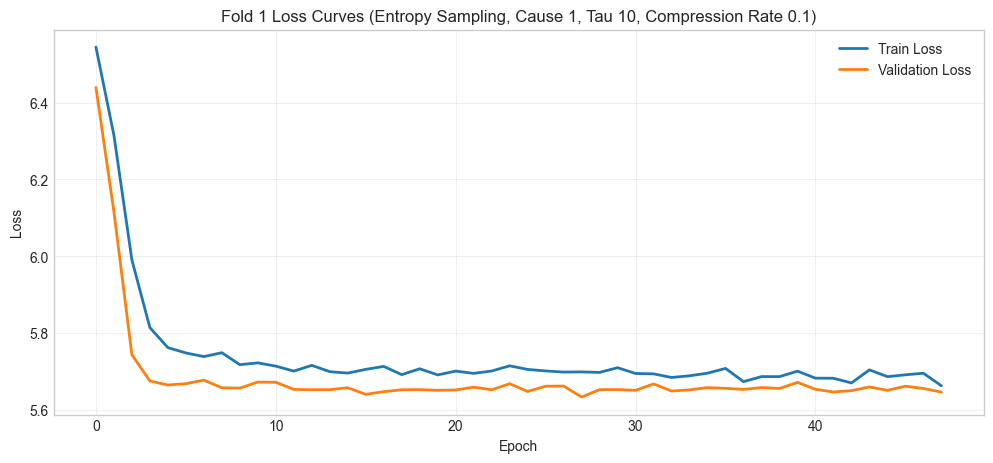

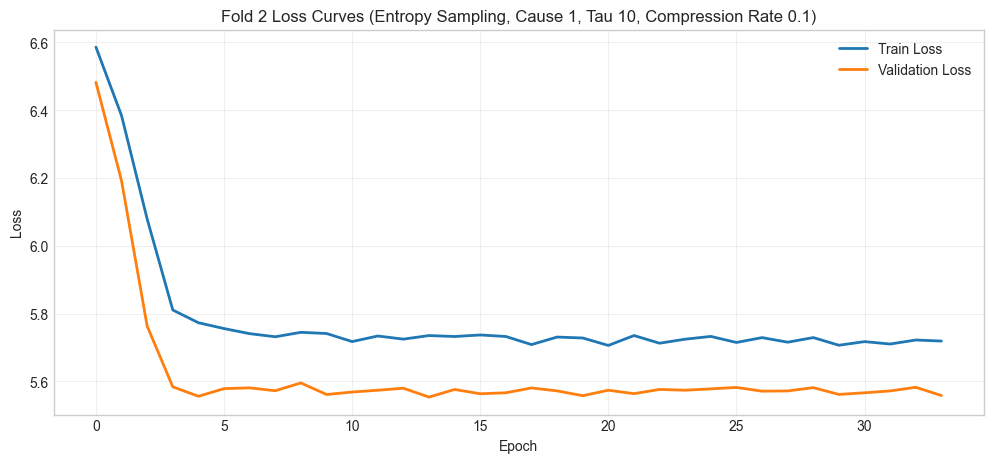

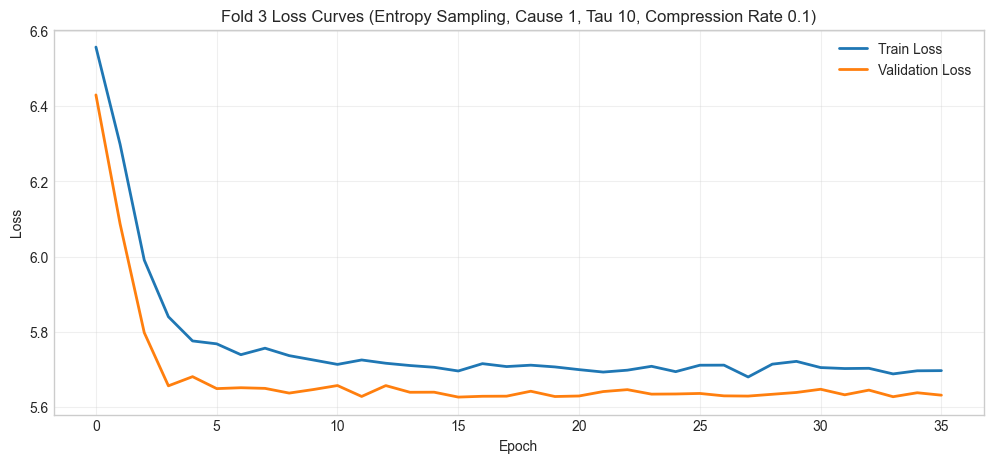

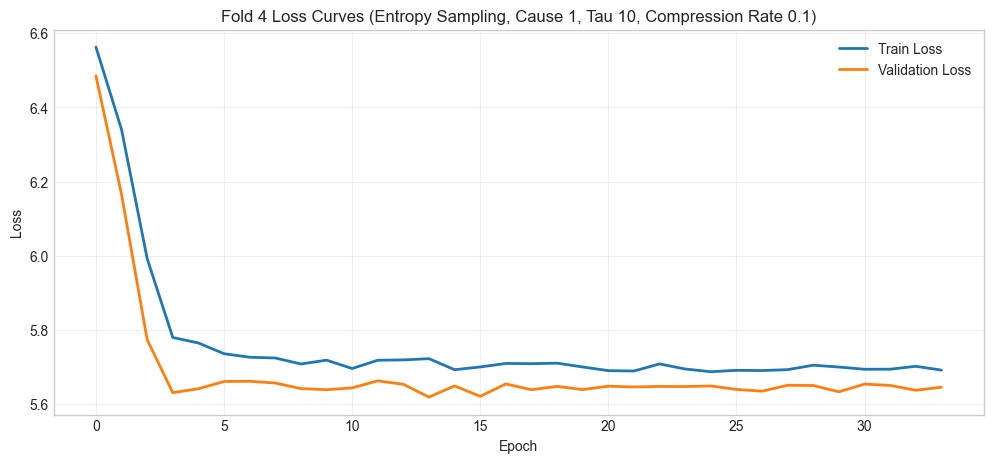

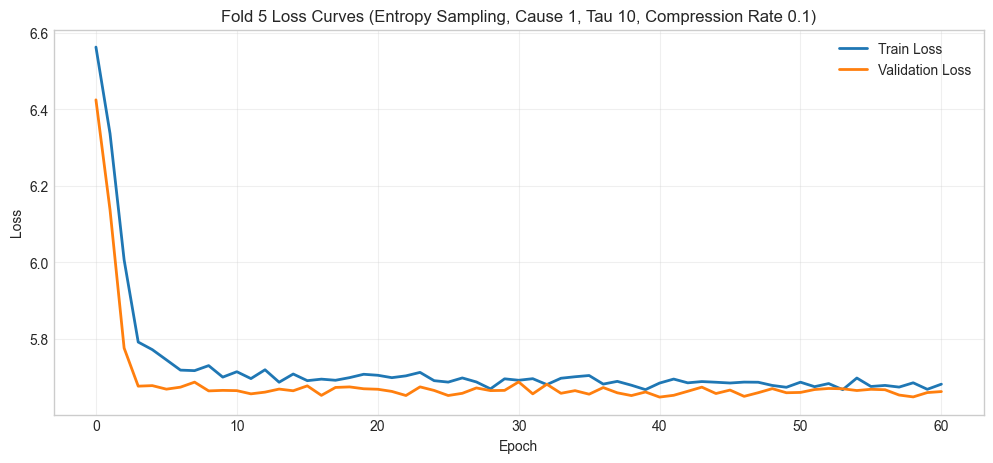

In [125]:

file_path = Path(f"../Results/{sample_type.name}/Loss")
file_path.mkdir(parents=True, exist_ok=True)



for fold_idx, history in enumerate(histories, start=1):
    plt.figure(figsize=(12, 5))

    plt.plot(history["train_loss"], label="Train Loss", linewidth=2)
    plt.plot(history["val_loss"], label="Validation Loss", linewidth=2)
    if sample_type == SamplerType.FULL.value:
        plt.title(f"Fold {fold_idx} Loss Curves (Full Cohort Sampling, Cause {model_cause})")
    if sample_type == SamplerType.SCC.value:
        plt.title(f"Fold {fold_idx} Loss Curves (Static Case-Cohort Sampling, Cause {model_cause}, Subcohort Fraction {subcohort_frac})")
    if sample_type == SamplerType.NCC.value:
        plt.title(f"Fold {fold_idx} Loss Curves (Nested Case-Control Sampling, Cause {model_cause}, n_controls {n_controls})")
    if sample_type == SamplerType.ENTROPY.value:
        plt.title(f"Fold {fold_idx} Loss Curves (Entropy Sampling, Cause {model_cause}, Tau {tau}, Compression Rate {compression_rate})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    if SamplerType.FULL == sample_type:
        plt.savefig(f"{file_path}/fold_{fold_idx}_loss_cause_{model_cause}.png", dpi=300, bbox_inches="tight")
    if SamplerType.SCC == sample_type:
        plt.savefig(f"{file_path}/fold_{fold_idx}_loss_cause_{model_cause}_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
    if SamplerType.NCC == sample_type:
        plt.savefig(f"{file_path}/fold_{fold_idx}_loss_cause_{model_cause}_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
    if SamplerType.ENTROPY == sample_type:
        plt.savefig(f"{file_path}/fold_{fold_idx}_loss_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path  
from pycox.evaluation import EvalSurv
from sksurv.nonparametric import kaplan_meier_estimator
from scipy.stats import spearmanr, pearsonr

def evaluate_and_compare_truth(
    all_test_predictions,
    all_test_indices,
    all_true_times,
    all_true_events,
    true_lp_1=None,
    true_lp_2=None,
    all_test_risk_scores=None,
    cause=1,
    time_grid=None,
):


    times = np.concatenate(all_true_times)
    events = np.concatenate(all_true_events)
    indices = np.concatenate(all_test_indices)

    n = indices.max() + 1
    full_times = np.zeros(n)
    full_events = np.zeros(n)
    full_times[indices] = times
    full_events[indices] = events

    # Define common evaluation grid
    if time_grid is None:
        raise ValueError("The original prediction time_grid is required.")

    common_grid = np.asarray(time_grid, dtype=np.float64)

    pooled = np.full((len(common_grid), n), np.nan)

    file_path = Path(f"../Results/{sample_type.name}/Metrics")
    file_path.parent.mkdir(parents=True, exist_ok=True)


    for fold_pred, fold_idx in zip(
        all_test_predictions, all_test_indices
    ):
        pred = np.asarray(fold_pred)

        # Ensure [time x patient] shape
        if pred.shape == (len(common_grid), len(fold_idx)):
            pass
        elif pred.shape == (len(fold_idx), len(common_grid)):
            pred = pred.T
        else:
            raise ValueError(
                f"Prediction shape {pred.shape} does not match "
                f"{len(common_grid)} times and {len(fold_idx)} patients."
            )

        # Predictions already correspond to common_grid
        pooled[:, fold_idx] = pred

    if np.isnan(pooled).any():
        raise ValueError("Missing pooled predictions in OOF aggregation.")


    surv_df = pd.DataFrame(pooled, index=common_grid)
    events_binary = (full_events == cause).astype(int)
    
    ev = EvalSurv(surv_df, durations=full_times, events=events_binary)

    # Censor estimate (IPCW)
    censor_mask = (full_events == 0)
    t_cens, p_cens = kaplan_meier_estimator(censor_mask, full_times)
    p_cens = np.clip(p_cens, 1e-8, 1)

    if t_cens[0] > 0:
        t_cens = np.insert(t_cens, 0, 0)
        p_cens = np.insert(p_cens, 0, 1)

    censor_df = pd.DataFrame(
        np.tile(p_cens[:, None], (1, n)),
        index=t_cens,
        columns=surv_df.columns
    )
    ev.add_censor_est(censor_df)

    eval_grid = np.asarray(common_grid, dtype=np.float64)
    c_index = ev.concordance_td("antolini")
    ibs_score = ev.integrated_brier_score(eval_grid)

    # Median Brier Score
    median_time = np.median(full_times)
    closest = eval_grid[np.abs(eval_grid - median_time).argmin()]
    normal_brier_score = float(ev.brier_score(np.array([closest])).iloc[0])

    print("\n===== POOLED OOF RESULTS =====")
    print(f"C-index: {c_index:.4f}")
    print(f"IBS: {ibs_score:.4f}")
    print(f"Brier: {normal_brier_score:.4f}")

    df_metrics = pd.DataFrame({
        "pooled_c_index": [c_index],
        "pooled_ibs": [ibs_score],
        "pooled_brier": [normal_brier_score]
    })

    if SamplerType.FULL == sample_type:
        df_metrics.to_csv(f"{file_path}/pooled_oof_metrics_cause_{cause}.csv", index=False)
    if SamplerType.SCC == sample_type:
        df_metrics.to_csv(f"{file_path}/pooled_oof_metrics_cause_{cause}_SCC_subcohort_{subcohort_frac}.csv", index=False)
    if SamplerType.NCC == sample_type:
        df_metrics.to_csv(f"{file_path}/pooled_oof_metrics_cause_{cause}_NCC_ncontrols_{n_controls}.csv", index=False)
    if SamplerType.ENTROPY == sample_type:
        df_metrics.to_csv(f"{file_path}/pooled_oof_metrics_cause_{cause}_Entropy_tau_{tau}_compression_{compression_rate}.csv", index=False)
        





    if all_test_risk_scores is not None:
        concatenated_scores = np.concatenate(all_test_risk_scores)
        pred_risk_scores = np.zeros(n)
        pred_risk_scores[indices] = concatenated_scores
    else:
        pred_risk_scores = None


    def plot_truth_comparison(true_lp, label, color, cmap, cause):
        true_lp = np.asarray(true_lp)
        s, _ = spearmanr(true_lp, pred_risk_scores)
        p, _ = pearsonr(true_lp, pred_risk_scores)

        print(f"\n{label} Truth Comparison")
        print(f"Spearman: {s:.4f} | Pearson: {p:.4f}")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        # Scatter
        sns.scatterplot(
            x=true_lp, y=pred_risk_scores, alpha=0.4, 
            color=color, edgecolor=None, ax=axes[0]
        )
        axes[0].set(xlabel=f"True Linear Predictor ({label})", 
                    ylabel="Pooled Risk (Median Time)", 
                    title=f"{label}: Truth vs Model (Cause: {cause})\nSpearman={s:.3f} | Pearson={p:.3f}")

        # Hexbin
        hb = axes[1].hexbin(
            true_lp, pred_risk_scores, gridsize=25, 
            cmap=cmap, mincnt=1
        )
        plt.colorbar(hb, label='Patient Density', ax=axes[1])
        axes[1].set(xlabel=f"True Linear Predictor ({label})", 
                    ylabel="Pooled Predicted Risk", 
                    title=f"{label} Space Density Map")
        

        fig.suptitle(f"Truth Comparison for Model (Cause: {cause}, Sample Type: {sample_type.name})", y=1.05)
        plt.tight_layout()
        
        if sample_type == SamplerType.FULL:
            plt.savefig(f"{file_path}/truth_comparison_{label.replace(' ', '_')}_cause_{cause}.png", dpi=300, bbox_inches="tight")
            plt.show()
        if sample_type == SamplerType.SCC:
            plt.savefig(f"{file_path}/truth_comparison_{label.replace(' ', '_')}_cause_{cause}_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
            plt.show()
        if sample_type == SamplerType.NCC:
            plt.savefig(f"{file_path}/truth_comparison_{label.replace(' ', '_')}_cause_{cause}_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
            plt.show()
        if sample_type == SamplerType.ENTROPY:
            plt.savefig(f"{file_path}/truth_comparison_{label.replace(' ', '_')}_cause_{cause}_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")
            plt.show()
        return p, s

    # Fixed: Cleanly saving the metrics based on whatever parameters are passed
    correlation_metrics = {}

    if true_lp_1 is not None and pred_risk_scores is not None:
        p1, s1 = plot_truth_comparison(true_lp_1, "Event 1", 'teal', 'viridis', cause)
        correlation_metrics["pearson_event1"] = p1
        correlation_metrics["spearman_event1"] = s1

    if true_lp_2 is not None and pred_risk_scores is not None:
        p2, s2 = plot_truth_comparison(true_lp_2, "Event 2", 'crimson', 'magma', cause)
        correlation_metrics["pearson_event2"] = p2
        correlation_metrics["spearman_event2"] = s2

    if correlation_metrics:
        df_corr = pd.DataFrame([correlation_metrics])
        if SamplerType.FULL == sample_type:
            df_corr.to_csv(f"{file_path}/truth_comparison_metrics_cause_{cause}.csv", index=False)
        if SamplerType.SCC == sample_type:
            df_corr.to_csv(f"{file_path}/truth_comparison_metrics_cause_{cause}_SCC_subcohort_{subcohort_frac}.csv", index=False)
        if SamplerType.NCC == sample_type:
            df_corr.to_csv(f"{file_path}/truth_comparison_metrics_cause_{cause}_NCC_ncontrols_{n_controls}.csv", index=False)
        if SamplerType.ENTROPY == sample_type:
            df_corr.to_csv(f"{file_path}/truth_comparison_metrics_cause_{cause}_Entropy_tau_{tau}_compression_{compression_rate}.csv", index=False)

    return c_index, ibs_score, normal_brier_score


===== POOLED OOF RESULTS =====
C-index: 0.8509
IBS: 0.1631
Brier: 0.1047

Event 1 Truth Comparison
Spearman: 0.8533 | Pearson: 0.8613


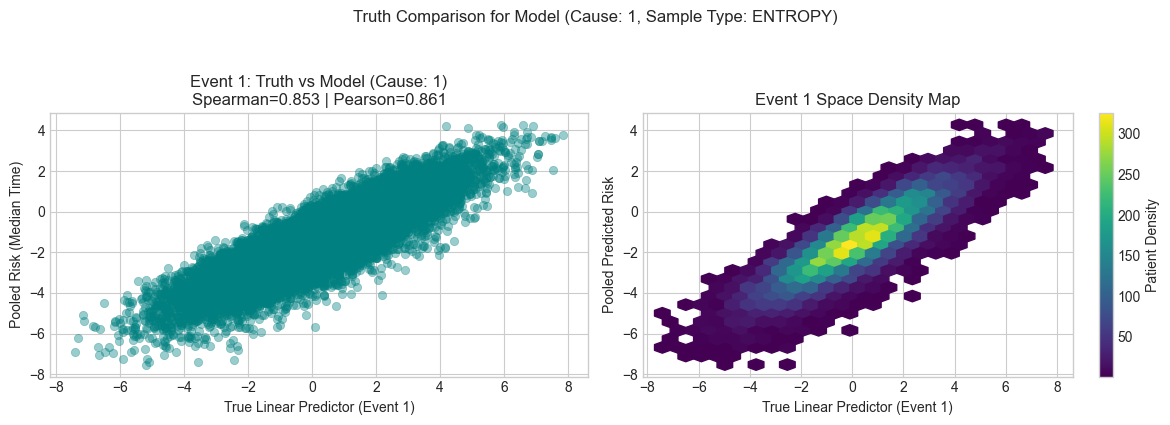


Event 2 Truth Comparison
Spearman: -0.3189 | Pearson: -0.3356


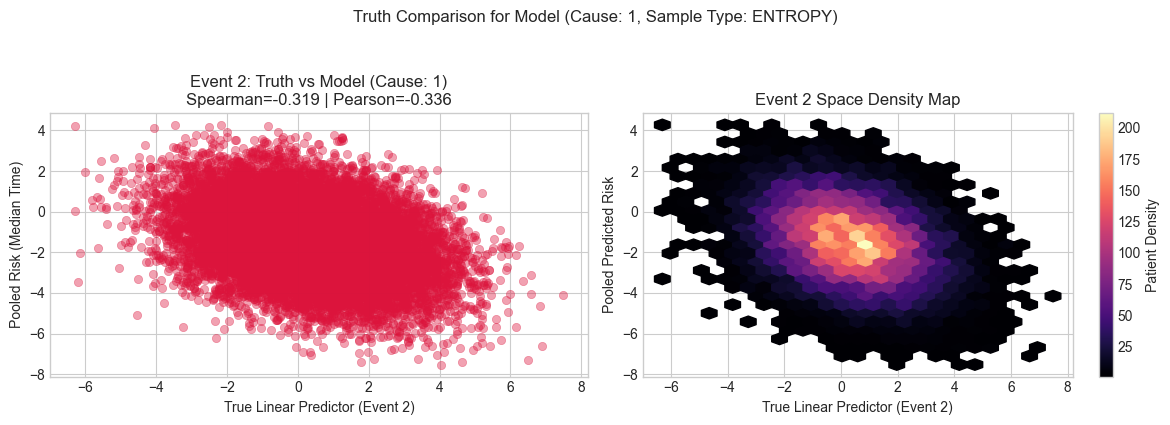

In [127]:
c_index, ibs_score, normal_brier_score = evaluate_and_compare_truth(
    all_test_predictions=all_test_predictions,
    all_test_indices=all_test_indices,
    all_true_times=all_true_times,
    all_true_events=all_true_events,
    true_lp_1=df["true_lp_event1"].values,
    true_lp_2=df["true_lp_event2"].values,
    all_test_risk_scores=all_test_risk_scores,
    cause=model_cause, # we do this so we do not forget to set the cause when evaluating the model as we do that the model
    time_grid=time_grid
)

In [128]:



import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path

def plot_event_contributions(
    feature_names,
    data_range_dict,
    true_betas,
    event_label,
    feature_nets,
    model_name,
    model_cause=1,
    model_trained_standardised=True,
    show_z_score_xaxis=False,
    rows=3,
    cols=4
):
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(rows, cols, figsize=(16, 12))
    axes = axes.flatten()

    for i, name in enumerate(feature_names):
        ax = axes[i]
        x = np.asarray(data_range_dict[name])
        mu, sigma = x.mean(), x.std() + 1e-8

        grid_raw = torch.linspace(x.min(), x.max(), 100).unsqueeze(1).float()
        
        # Standardise model inputs if training used z-scores
        grid_model = (grid_raw - mu) / sigma if model_trained_standardised else grid_raw
        x_plot = (grid_raw.numpy().flatten() - mu) / sigma if show_z_score_xaxis else grid_raw.numpy().flatten()

        net = feature_nets[i]
        with torch.no_grad():
            learned = net(grid_model).cpu().numpy().flatten()

        true_val = grid_raw.numpy().flatten() * true_betas[i]

        # Mean-center both to remove arbitrary global bias shift
        learned = learned - np.mean(learned)
        true_val = true_val - np.mean(true_val)

        ax.plot(x_plot, learned, color='#2c3e50', linewidth=2.5, label='Learned')
        ax.plot(x_plot, true_val, color='#e74c3c', linestyle='--', linewidth=2, label='True βx')

        ax.set_title(f"{name} (β={true_betas[i]:.3f})", fontsize=11)
        ax.set_ylabel("Contribution (Centered)")
        ax.set_xlabel("Standardised Feature (z-score)" if show_z_score_xaxis else "Feature Value")
        ax.legend(fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.5)

    for j in range(len(feature_names), len(axes)):
        axes[j].axis('off')

    plt.suptitle(
        f"{event_label}: Feature Contribution Recovery\n{model_name}",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    output_dir = Path(f"../Results/{sample_type.name}/FeatureContributions")
    output_dir.mkdir(parents=True, exist_ok=True)
    if SamplerType.FULL == sample_type:
        plt.savefig(output_dir / f"feature_contributions_{event_label.replace(' ', '_')}_cause_{model_cause}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.SCC == sample_type:
        plt.savefig(output_dir / f"feature_contributions_{event_label.replace(' ', '_')}_cause_{model_cause}_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.NCC == sample_type:
        plt.savefig(output_dir / f"feature_contributions_{event_label.replace(' ', '_')}_cause_{model_cause}_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.ENTROPY == sample_type:
        plt.savefig(output_dir / f"feature_contributions_{event_label.replace(' ', '_')}_cause_{model_cause}_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")
        plt.show()
    

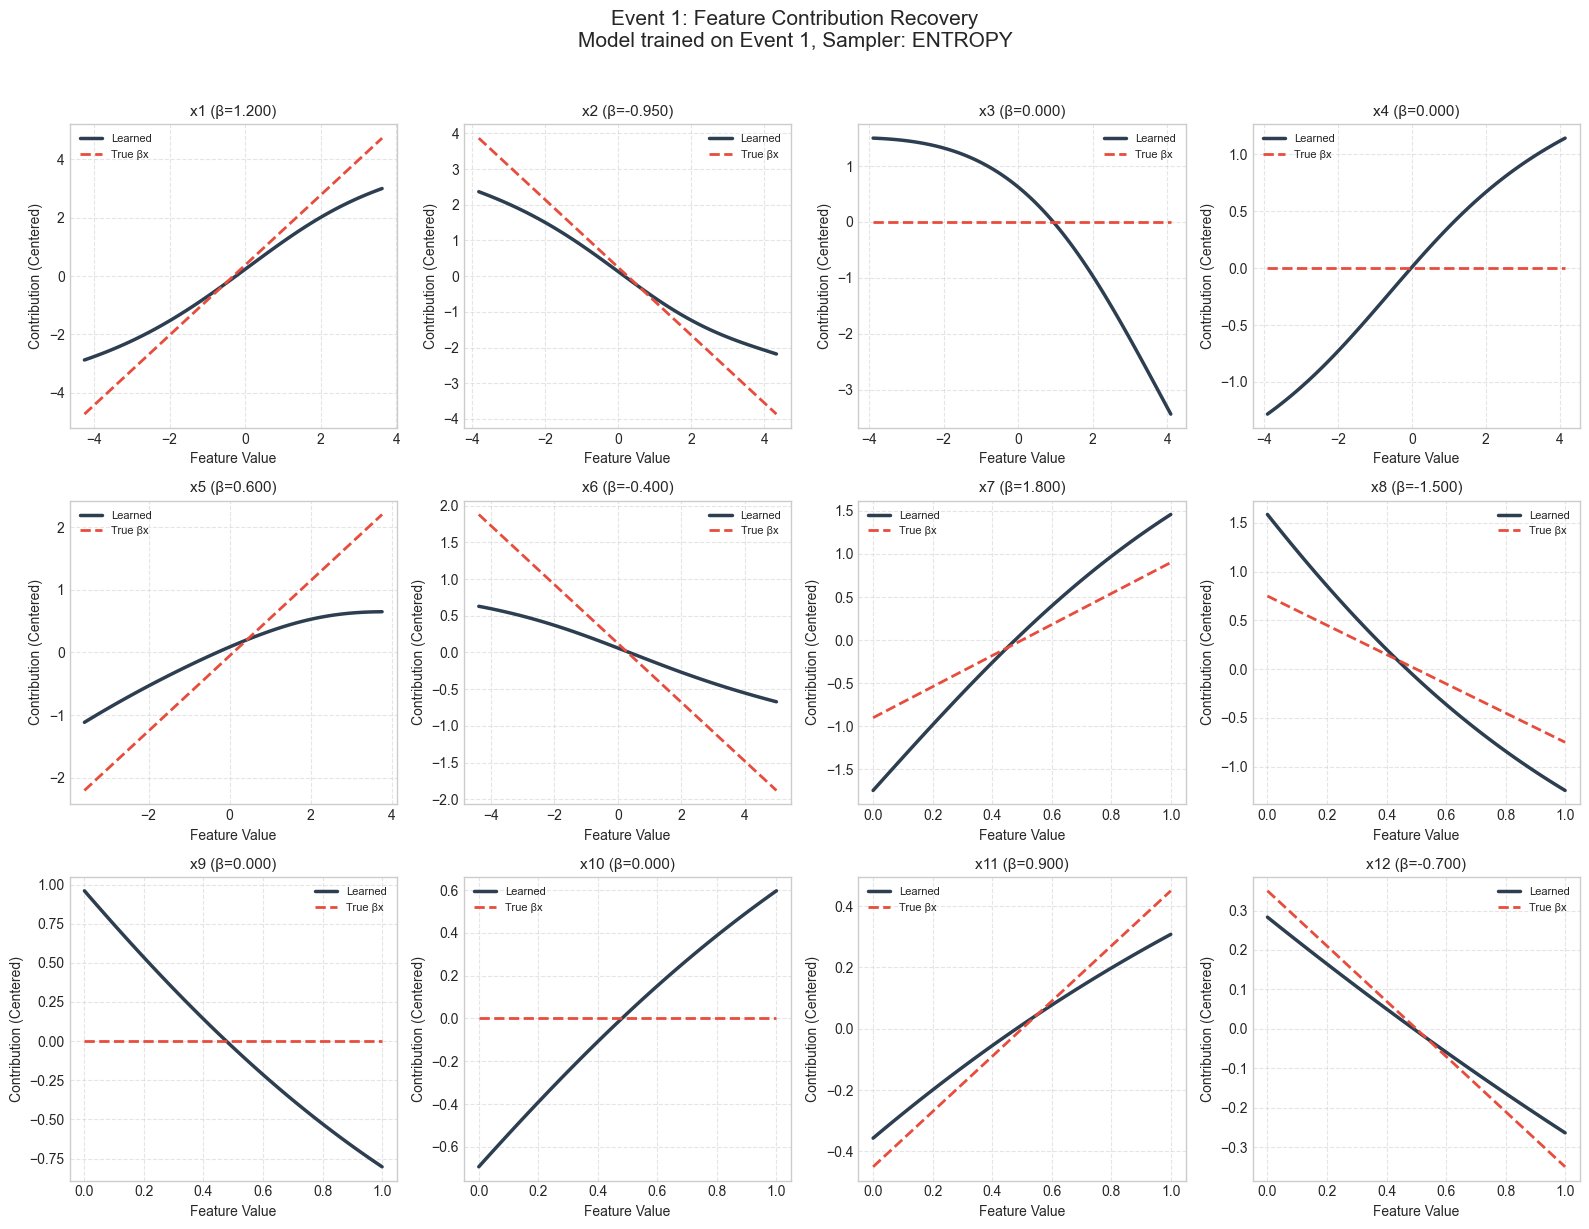

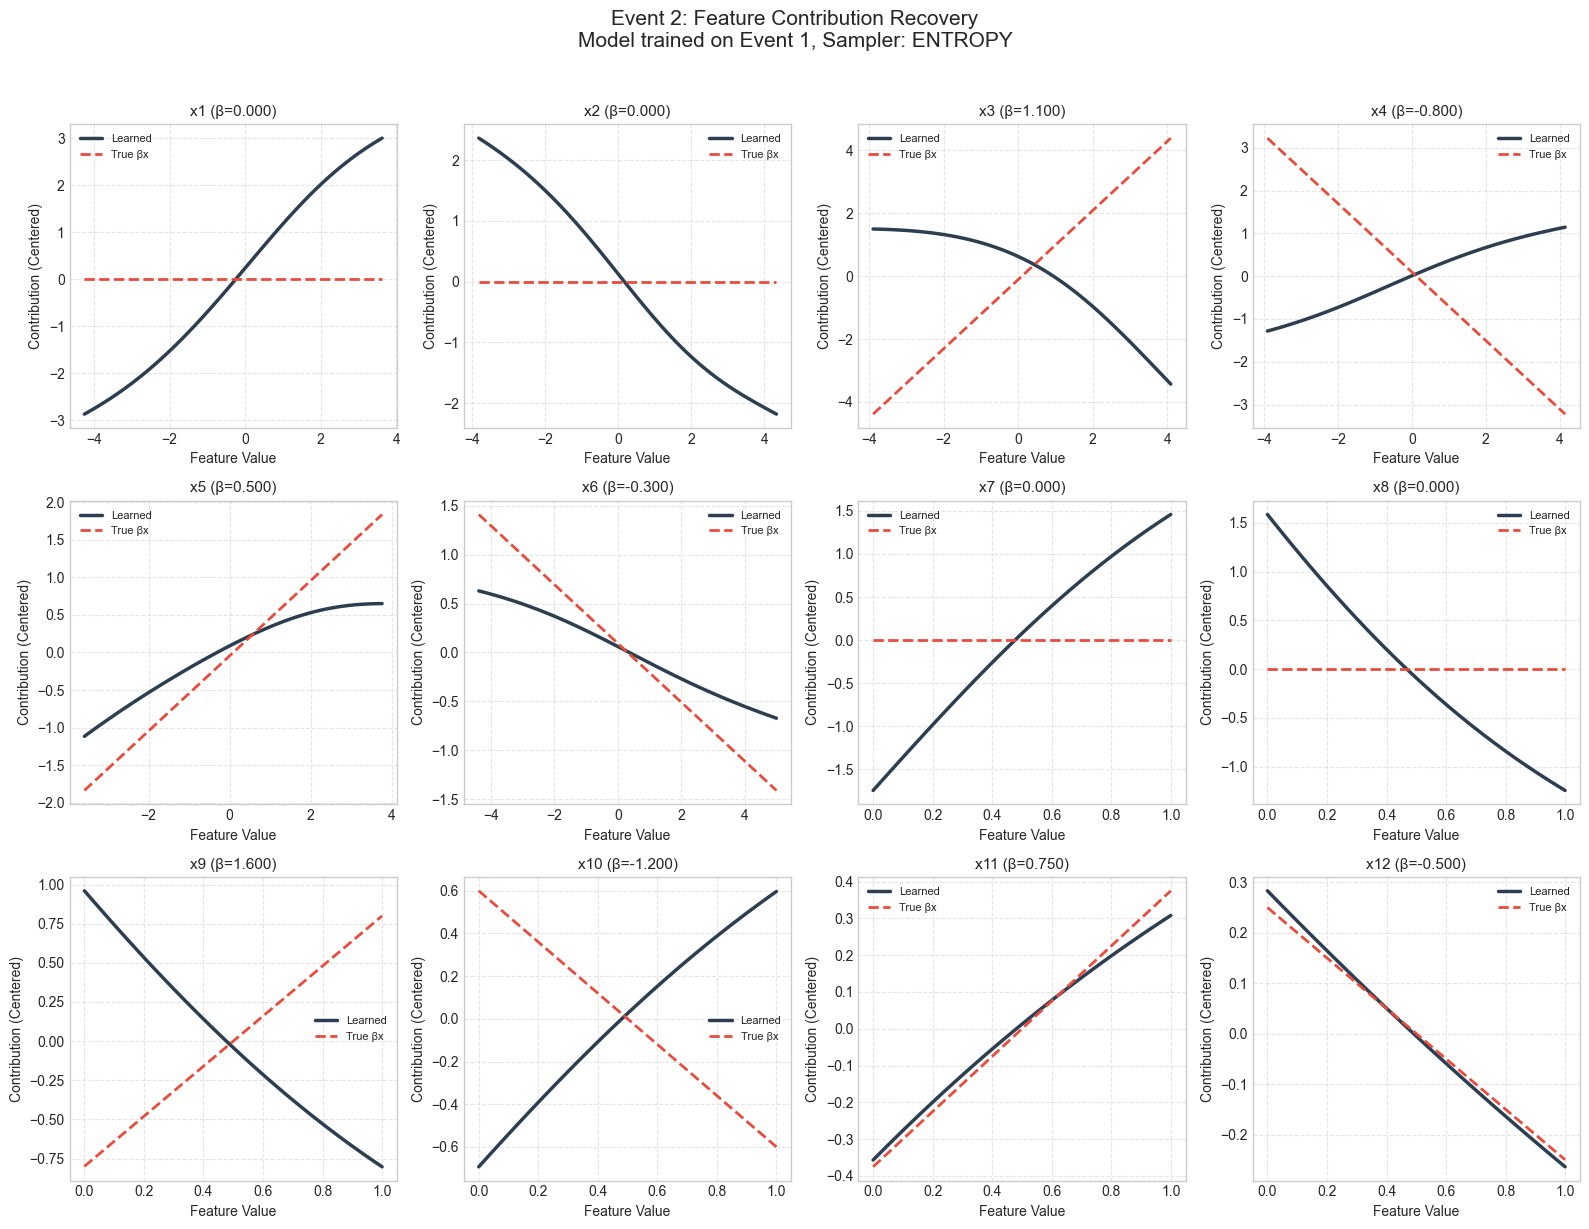

In [129]:
feature_names = df_synthetic.drop(['time', 'event', 'true_lp_event1', 'true_lp_event2'], axis=1).columns.tolist()

data_dict = {name: df_synthetic[name] for name in feature_names}

# --- Execution ---
# Run for Event 1
plot_event_contributions(
    feature_names=feature_names,
    data_range_dict=data_dict,
    true_betas=true_beta_event1,
    event_label="Event 1",
    feature_nets=models[0].feature_nets,  # or model.feature_nets[0]
    model_name=f"Model trained on Event {model_cause}, Sampler: {sample_type.name}",
    cols=4, rows=3
)

# Run for Event 2
plot_event_contributions(
    feature_names=feature_names,
    data_range_dict=data_dict,
    true_betas=true_beta_event2,
    event_label="Event 2",
    feature_nets=models[0].feature_nets,  # or model.feature_nets[0]
    model_name=f"Model trained on Event {model_cause}, Sampler: {sample_type.name}",
    cols=4, rows=3
)

## CPU, Memmory and Training Metrics


===== Fold 1 Resource Usage =====
           time     cpu      memory
0  1.791992e+09     0.0  782.792969
1  1.791992e+09  1184.4  820.601562
2  1.791992e+09  1196.1  821.750000
3  1.791992e+09  1069.6  639.222656
4  1.791992e+09  1162.0  639.222656


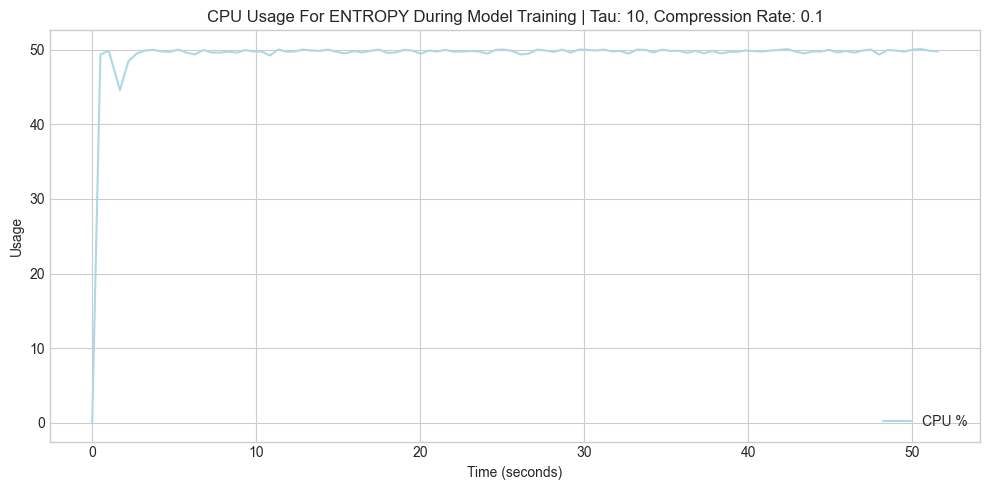


===== Fold 2 Resource Usage =====
           time     cpu      memory
0  1.791992e+09     0.0  879.890625
1  1.791992e+09  1359.4  894.601562
2  1.791992e+09  1189.3  894.601562
3  1.791992e+09  1187.0  892.109375
4  1.791992e+09  1196.9  894.609375


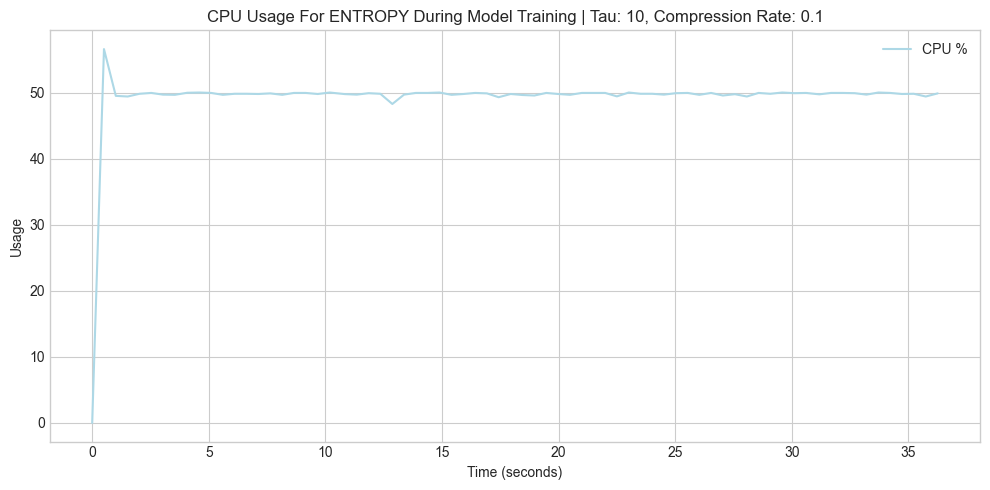


===== Fold 3 Resource Usage =====
           time     cpu      memory
0  1.791992e+09     0.0  858.425781
1  1.791992e+09  1311.2  891.777344
2  1.791992e+09  1193.1  892.871094
3  1.791992e+09  1184.4  896.058594
4  1.791992e+09  1201.5  896.058594


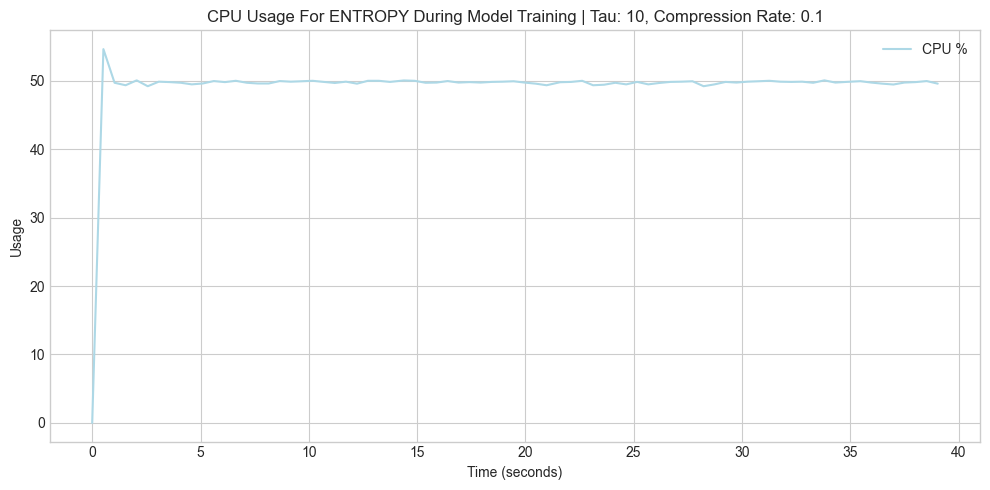


===== Fold 4 Resource Usage =====
           time     cpu      memory
0  1.791992e+09     0.0  884.175781
1  1.791992e+09  1346.9  901.468750
2  1.791992e+09  1187.0  901.710938
3  1.791992e+09  1190.6  901.687500
4  1.791992e+09  1198.4  901.691406


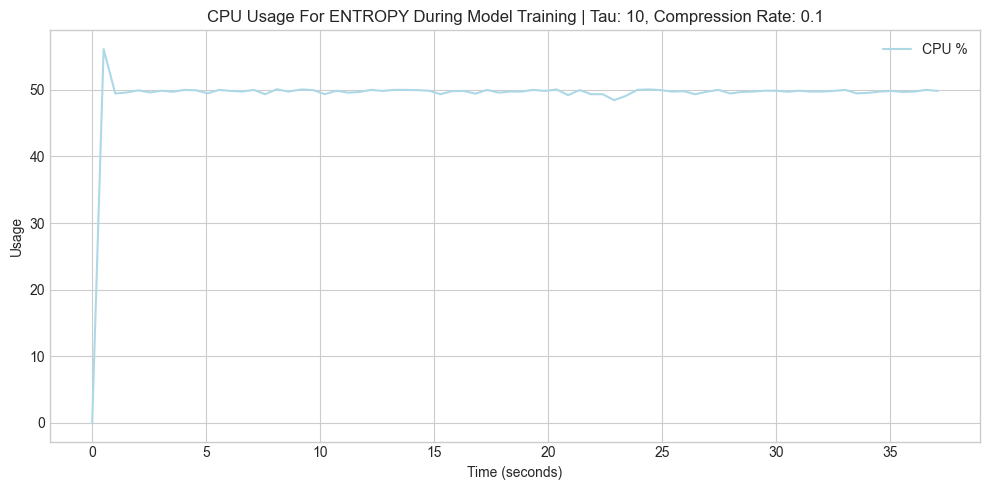


===== Fold 5 Resource Usage =====
           time     cpu      memory
0  1.791992e+09     0.0  864.078125
1  1.791992e+09  1344.1  894.976562
2  1.791992e+09  1196.1  895.527344
3  1.791992e+09  1193.8  900.625000
4  1.791992e+09  1196.1  900.285156


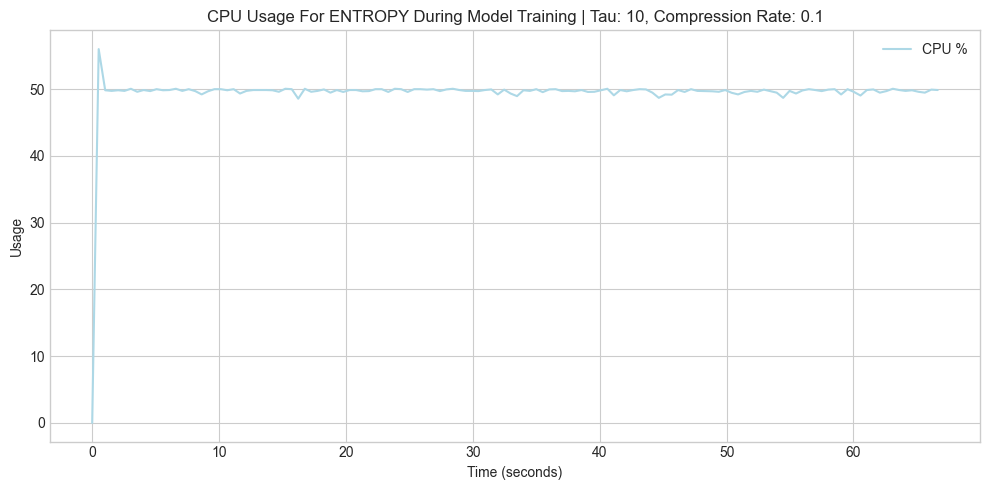

In [130]:

output_dir = Path(f"../Results/{sample_type.name}/ResourceUsage/CPU_Usage_cause_{model_cause}")
output_dir.mkdir(parents=True, exist_ok=True)


for fold, resource_log in enumerate(fold_resource_logs, start=1):
    print(f"\n===== Fold {fold} Resource Usage =====")
    print(resource_log.head())
    resource_log['time'] = resource_log['time'] - resource_log['time'].iloc[0]
    plt.figure(figsize=(10, 5))
    num_cores = psutil.cpu_count(logical=True)
    resource_log['cpu_normalized'] = resource_log['cpu'] / num_cores
    plt.plot(resource_log['time'], resource_log['cpu_normalized'], label='CPU %', color='lightblue')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Usage')


    if SamplerType.SCC == sample_type:
        plt.title(f'CPU Usage For {sample_type.name} During Model Training | Subcohort Fraction: {subcohort_frac}')
    if SamplerType.NCC == sample_type:
        plt.title(f'CPU Usage For {sample_type.name} During Model Training | nControls: {n_controls}')
    if SamplerType.ENTROPY == sample_type:
        plt.title(f'CPU Usage For {sample_type.name} During Model Training | Tau: {tau}, Compression Rate: {compression_rate}')
    if SamplerType.FULL == sample_type:
        plt.title(f'CPU Usage For {sample_type.name} During Model Training')


    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    if SamplerType.FULL == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_resource_usage.png", dpi=300, bbox_inches="tight")
    if SamplerType.SCC == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_resource_usage_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
    if SamplerType.NCC == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_resource_usage_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
    if SamplerType.ENTROPY == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_resource_usage_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")

    plt.show()


===== Fold 1 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  782.792969        0.000000
1  0.501129  1184.4  820.601562       49.350000
2  1.012169  1196.1  821.750000       49.837500
3  1.688005  1069.6  639.222656       44.566667
4  2.204042  1162.0  639.222656       48.416667


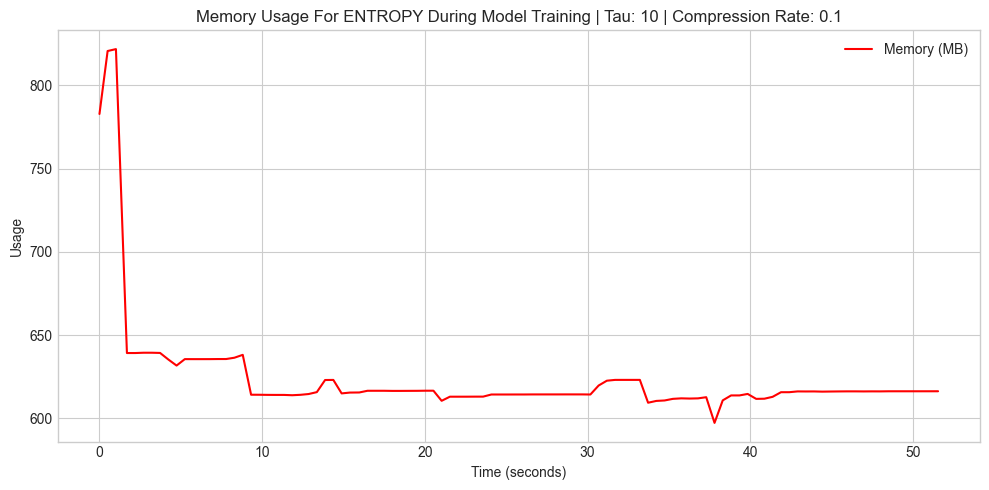


===== Fold 2 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  879.890625        0.000000
1  0.505160  1359.4  894.601562       56.641667
2  1.012788  1189.3  894.601562       49.554167
3  1.524815  1187.0  892.109375       49.458333
4  2.029097  1196.9  894.609375       49.870833


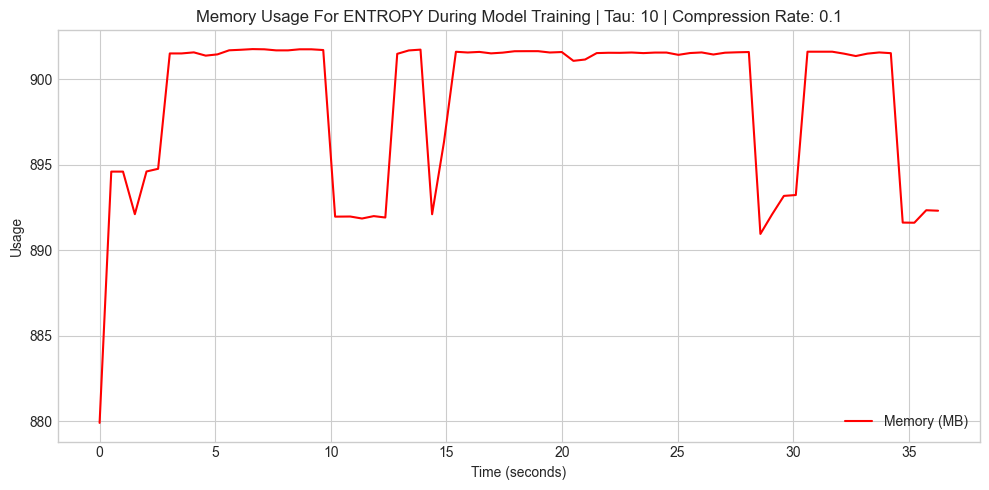


===== Fold 3 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  858.425781        0.000000
1  0.517470  1311.2  891.777344       54.633333
2  1.032459  1193.1  892.871094       49.712500
3  1.542923  1184.4  896.058594       49.350000
4  2.053404  1201.5  896.058594       50.062500


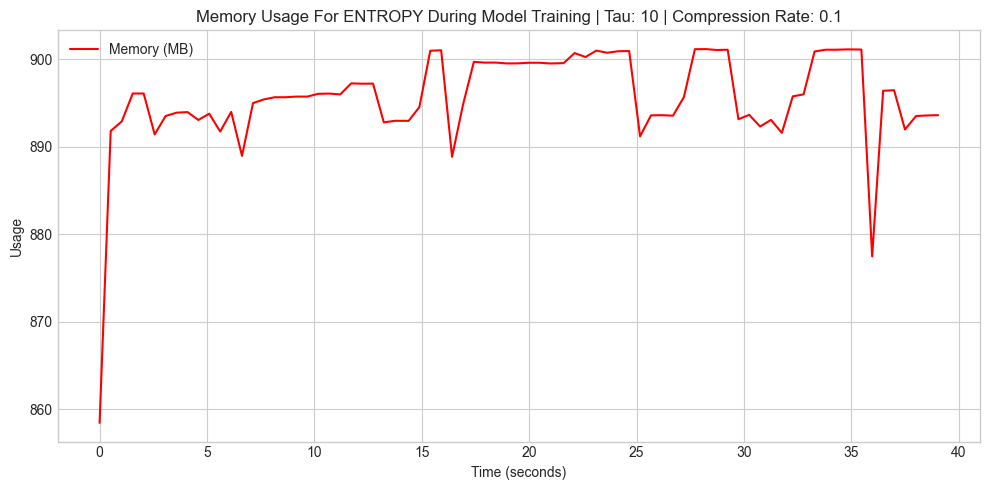


===== Fold 4 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  884.175781        0.000000
1  0.501378  1346.9  901.468750       56.120833
2  1.011364  1187.0  901.710938       49.458333
3  1.518380  1190.6  901.687500       49.608333
4  2.023073  1198.4  901.691406       49.933333


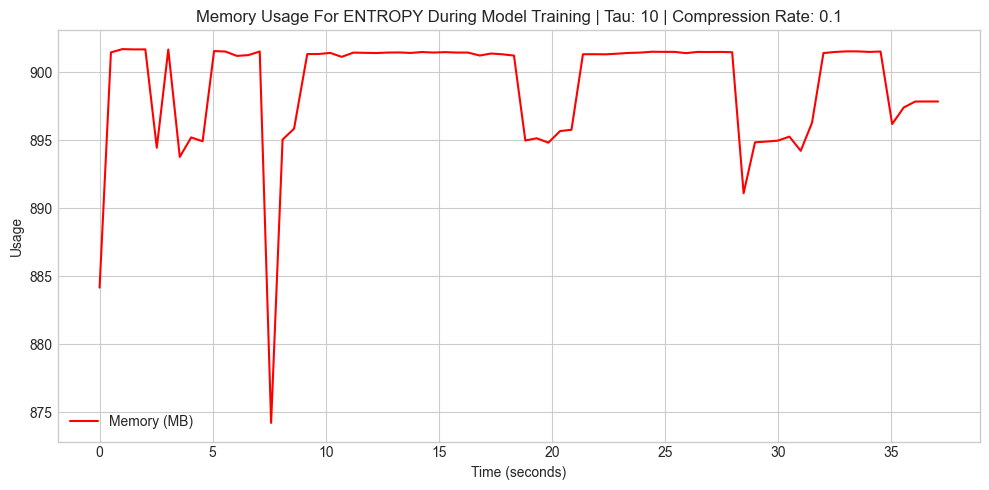


===== Fold 5 Resource Usage =====
       time     cpu      memory  cpu_normalized
0  0.000000     0.0  864.078125        0.000000
1  0.512071  1344.1  894.976562       56.004167
2  1.024857  1196.1  895.527344       49.837500
3  1.530360  1193.8  900.625000       49.741667
4  2.040455  1196.1  900.285156       49.837500


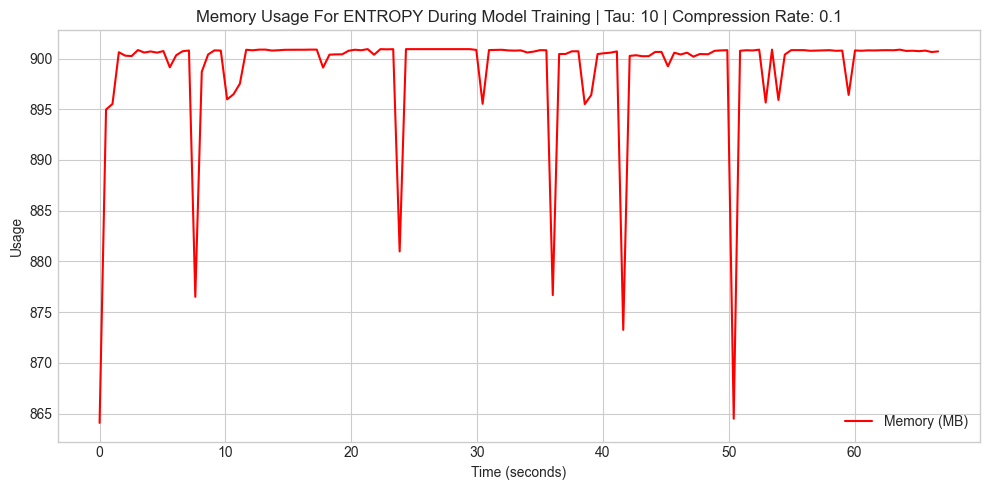

In [131]:

output_dir = Path(f"../Results/{sample_type.name}/ResourceUsage/Memory_Usage_cause_{model_cause}")


output_dir.mkdir(parents=True, exist_ok=True)


for fold, resource_log in enumerate(fold_resource_logs, start=1):
    print(f"\n===== Fold {fold} Resource Usage =====")
    print(resource_log.head())

    resource_log['time'] = resource_log['time'] - resource_log['time'].iloc[0]

    plt.figure(figsize=(10, 5))
    plt.plot(resource_log['time'], resource_log['memory'], label='Memory (MB)', color='red')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Usage')


    if SamplerType.SCC == sample_type:
        plt.title(f'Memory Usage For {sample_type.name} During Model Training | Subcohort Fraction: {subcohort_frac}')
    if SamplerType.NCC == sample_type:
        plt.title(f'Memory Usage For {sample_type.name} During Model Training | nControls: {n_controls}')
    if SamplerType.ENTROPY == sample_type:
        plt.title(f'Memory Usage For {sample_type.name} During Model Training | Tau: {tau} | Compression Rate: {compression_rate}')
    if SamplerType.FULL == sample_type:
        plt.title(f'Memory Usage For {sample_type.name} During Model Training')


    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    if SamplerType.FULL == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_memory_usage.png", dpi=300, bbox_inches="tight")
    if SamplerType.SCC == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_memory_usage_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
    if SamplerType.NCC == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_memory_usage_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
    if SamplerType.ENTROPY == sample_type:
        plt.savefig(f"{output_dir}/fold_{fold}_memory_usage_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from lifelines import AalenJohansenFitter

def plot_crispnam_diagnostics(
    true_lp: np.ndarray,
    pred_risk_scores: np.ndarray,
    pred_cif: np.ndarray,        # Shape: (n_samples, n_time_points)
    time_grid: np.ndarray,
    times: np.ndarray,
    events: np.ndarray,
    cause: int = 1,
    q_strata: int = 3
):
    """
    Generates diagnostic plots for competing risks:
    1. True LP vs Predicted Risk Score scatter + correlation
    2. Stratified Predicted CIF vs Empirical Aalen-Johansen CIF
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # -----------------------------------------------------------------
    # Plot 1: True Linear Predictor vs Predicted Risk Score
    # -----------------------------------------------------------------
    rho, _ = spearmanr(true_lp, pred_risk_scores)
    r, _ = pearsonr(true_lp, pred_risk_scores)
    
    sns.scatterplot(x=true_lp, y=pred_risk_scores, alpha=0.4, color='royalblue', ax=axes[0])
    sns.regplot(x=true_lp, y=pred_risk_scores, scatter=False, color='crimson', ax=axes[0])
    axes[0].set_title(f"Risk Score Recovery (Cause {cause})\nSpearman ρ: {rho:.3f} | Pearson r: {r:.3f}", fontsize=12)
    axes[0].set_xlabel("True Linear Predictor (Ground Truth)")
    axes[0].set_ylabel("Predicted Risk Score ($\\hat{\\eta}$)")
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # -----------------------------------------------------------------
    # Plot 2: Stratified CIF Calibration (Predicted vs Aalen-Johansen)
    # -----------------------------------------------------------------
    # Stratify patients into quantiles (e.g., Low, Medium, High)
    strata_labels = [f"Stratum {i+1}" for i in range(q_strata)]
    risk_groups = pd.qcut(pred_risk_scores, q=q_strata, labels=strata_labels)
    palette = sns.color_palette("tab10", q_strata)

    df_eval = pd.DataFrame({
        'time': times,
        'event': events,
        'group': risk_groups
    })

    for idx, label in enumerate(strata_labels):
        mask = (risk_groups == label)
        color = palette[idx]
        
        # 1. Model Predicted Mean CIF
        mean_pred_cif = pred_cif[mask].mean(axis=0)
        axes[1].plot(time_grid, mean_pred_cif, label=f"Model: {label}", color=color, lw=2)

        # 2. Empirical Aalen-Johansen CIF
        ajf = AalenJohansenFitter(calculate_variance=False)
        sub_df = df_eval[mask]
        ajf.fit(
            durations=sub_df['time'], 
            event_observed=sub_df['event'], 
            event_of_interest=cause
        )
        
        aj_curve = ajf.cumulative_density_
        axes[1].plot(
            aj_curve.index, 
            aj_curve.iloc[:, 0], 
            linestyle="--", 
            alpha=0.7, 
            color=color, 
            label=f"Empirical AJ: {label}"
        )

    axes[1].set_title(f"Stratified CIF Calibration (Cause {cause})", fontsize=12)
    axes[1].set_xlabel("Time")
    axes[1].set_ylabel(f"Cumulative Incidence $F_{cause}(t)$")
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
    axes[1].grid(True, linestyle="--", alpha=0.5)
    if SamplerType.FULL == sample_type:
        fig.suptitle(f"Model Diagnostics for Cause {cause} (Sample Type: {sample_type.name})", fontsize=14, fontweight='bold', y=1.05)
    if SamplerType.SCC == sample_type:
        fig.suptitle(f"Model Diagnostics for Cause {cause} (Sample Type: {sample_type.name}, Subcohort Fraction: {subcohort_frac})", fontsize=14, fontweight='bold', y=1.05)
    if SamplerType.NCC == sample_type:
        fig.suptitle(f"Model Diagnostics for Cause {cause} (Sample Type: {sample_type.name}, nControls: {n_controls})", fontsize=14, fontweight='bold', y=1.05)
    if SamplerType.ENTROPY == sample_type:
        fig.suptitle(f"Model Diagnostics for Cause {cause} (Sample Type: {sample_type.name}, Tau: {tau}, Compression Rate: {compression_rate})", fontsize=14, fontweight='bold', y=1.05)

    plt.tight_layout()
    output_dir = Path(f"../Results/{sample_type.name}/Metrics")
    output_dir.mkdir(parents=True, exist_ok=True)
    if SamplerType.FULL == sample_type:
        plt.savefig(f"{output_dir}/model_diagnostics_cause_{cause}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.SCC == sample_type:
        plt.savefig(f"{output_dir}/model_diagnostics_cause_{cause}_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.NCC == sample_type:
        plt.savefig(f"{output_dir}/model_diagnostics_cause_{cause}_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.ENTROPY == sample_type:
        plt.savefig(f"{output_dir}/model_diagnostics_cause_{cause}_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")
        plt.show()

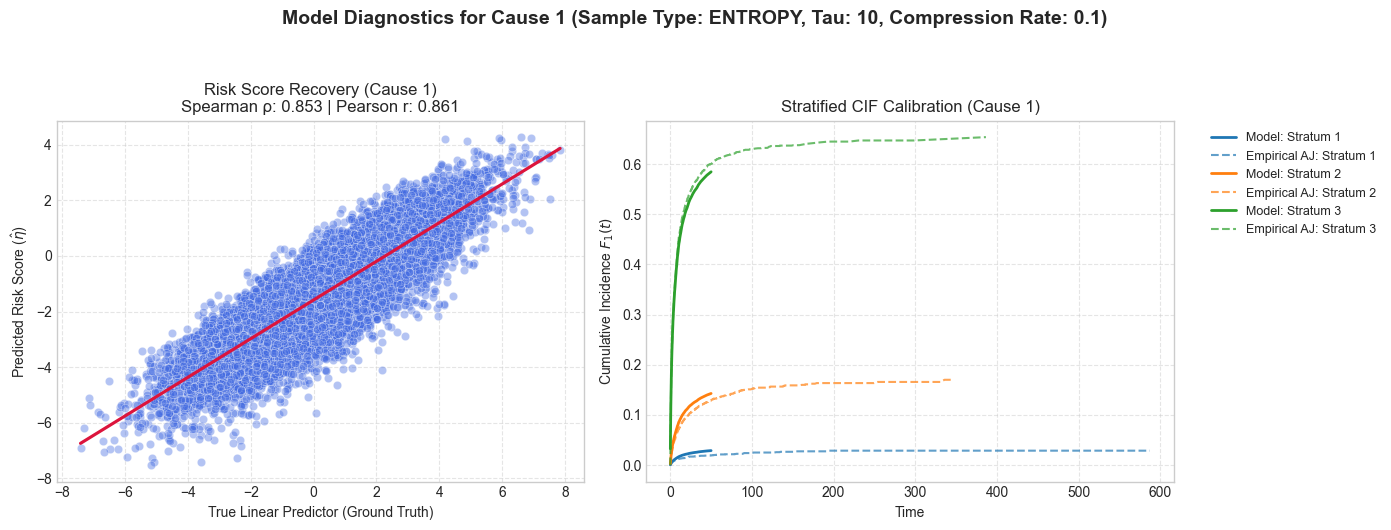

In [133]:
# -------------------------------------------------------------------------
# 1. Unpack and Format OOF Arrays
# -------------------------------------------------------------------------
oof_preds_surv = np.vstack(all_test_predictions)       # Shape: (N_total, len(time_grid)) - Survival S_1(t)
oof_preds_cif = 1.0 - oof_preds_surv                   # Cumulative Incidence Function F_1(t)

oof_risk_scores = np.concatenate(all_test_risk_scores) # Raw predicted log-hazard eta
oof_times = np.concatenate(all_true_times)
oof_events = np.concatenate(all_true_events)
oof_indices = np.concatenate(all_test_indices)

# Retrieve Ground Truth LP matching OOF test order
oof_true_lp = df.iloc[oof_indices]['true_lp_event1'].values

# -------------------------------------------------------------------------
# 2. Run Diagnostics (Truth vs. Model & Stratified AJ CIF)
# -------------------------------------------------------------------------
plot_crispnam_diagnostics(
    true_lp=oof_true_lp,
    pred_risk_scores=oof_risk_scores,
    pred_cif=oof_preds_cif,
    time_grid=time_grid,
    times=oof_times,
    events=oof_events,
    cause=model_cause
)

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import AalenJohansenFitter, KaplanMeierFitter

def plot_subject_curves_with_reference(
    time_grid: np.ndarray,
    pred_cif: np.ndarray,              # Shape: (N_samples, N_time_points)
    risk_scores: np.ndarray,           # Shape: (N_samples,)
    times: np.ndarray,                 # True event/censoring times of cohort
    events: np.ndarray,                # True event indicators of cohort
    cause: int = 1,                    # Event of interest
    true_lp: np.ndarray = None,        # Optional: Ground truth linear predictor
    n_extremes: int = 4,               # Number of high/low patients
    n_random: int = 5,                 # Number of random patients
    curve_type: str = "cif",           # "cif" (Cumulative Incidence) or "survival" (1 - CIF)
    seed: int = 42,
    title: str = "Empty Title"
):
    """
    Plots individual subject trajectories with an unconditioned empirical
    baseline (Aalen-Johansen / Kaplan-Meier) reference curve.
    """
    np.random.seed(seed)
    n_samples = len(risk_scores)
    
    # -------------------------------------------------------------
    # 1. Compute Empirical Population Reference Curve
    # -------------------------------------------------------------
    # In competing risks, Aalen-Johansen represents the population CIF
    ajf = AalenJohansenFitter(calculate_variance=False)
    ajf.fit(durations=times, event_observed=events, event_of_interest=cause)
    
    # Interpolate population reference onto the exact same time_grid
    ref_cif_series = ajf.cumulative_density_.iloc[:, 0]
    pop_ref_cif = np.interp(time_grid, ref_cif_series.index, ref_cif_series.values)
    
    # Switch between CIF and Survival (1 - CIF)
    if curve_type == "cif":
        subject_curves = pred_cif
        pop_ref_curve = pop_ref_cif
        ylabel = f"Cumulative Incidence $F_{cause}(t)$"
        ref_label = "Population Reference (Aalen-Johansen CIF)"
    else:
        subject_curves = 1.0 - pred_cif
        pop_ref_curve = 1.0 - pop_ref_cif
        ylabel = f"Subdistribution Survival $S_{cause}(t)$"
        ref_label = "Population Reference (Marginal Survival)"

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    
    # -------------------------------------------------------------
    # Subplot 1: Extreme High vs. Low Risk + Reference Line
    # -------------------------------------------------------------
    sorted_indices = np.argsort(risk_scores)
    low_risk_idx = sorted_indices[:n_extremes]
    high_risk_idx = sorted_indices[-n_extremes:]
    
    # Plot Population Reference Line first
    axes[0].plot(
        time_grid, 
        pop_ref_curve, 
        color="black", 
        linestyle="--", 
        linewidth=2.5, 
        label=ref_label,
        zorder=5
    )
    
    # Low-Risk Subjects (Solid Blue)
    for i, idx in enumerate(low_risk_idx):
        axes[0].plot(
            time_grid, 
            subject_curves[idx], 
            color="navy", 
            alpha=0.6, 
            linewidth=1.8,
            label="Low-Risk Subjects" if i == 0 else ""
        )
        
    # High-Risk Subjects (Solid Red)
    for i, idx in enumerate(high_risk_idx):
        axes[0].plot(
            time_grid, 
            subject_curves[idx], 
            color="crimson", 
            alpha=0.6, 
            linewidth=1.8,
            label="High-Risk Subjects" if i == 0 else ""
        )
        
    axes[0].set_title(f"Separation: High vs. Low Risk vs. Population Baseline", fontsize=12)
    axes[0].set_xlabel("Time")
    axes[0].set_ylabel(ylabel)
    axes[0].legend(loc="best", frameon=True)
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # -------------------------------------------------------------
    # Subplot 2: Randomly Sampled Subjects + Reference Line
    # -------------------------------------------------------------
    random_indices = np.random.choice(n_samples, size=n_random, replace=False)
    random_indices = random_indices[np.argsort(risk_scores[random_indices])]
    palette = sns.color_palette("turbo", n_random)
    
    # Plot Population Reference Line
    axes[1].plot(
        time_grid, 
        pop_ref_curve, 
        color="black", 
        linestyle="--", 
        linewidth=2.5, 
        label=ref_label,
        zorder=5
    )
    
    # Plot Individual Random Subjects
    for i, idx in enumerate(random_indices):
        score = risk_scores[idx]
        lbl = f"Subject #{idx} ($\\hat{{\\eta}}$={score:.2f})"
        if true_lp is not None:
            lbl += f" [True LP={true_lp[idx]:.2f}]"
            
        axes[1].plot(
            time_grid, 
            subject_curves[idx], 
            color=palette[i], 
            linewidth=2, 
            label=lbl
        )
        
    axes[1].set_title(f"Individual Patient Trajectories vs. Population Baseline", fontsize=12)
    axes[1].set_xlabel("Time")
    axes[1].set_ylabel(ylabel)
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
    axes[1].grid(True, linestyle="--", alpha=0.5)
    
    plt.tight_layout()
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.05)
    output_dir = Path(f"../Results/{sample_type.name}/Metrics")
    output_dir.mkdir(parents=True, exist_ok=True)
    if SamplerType.FULL == sample_type:
        plt.savefig(f"{output_dir}/subject_curves_cause_{cause}_{curve_type}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.SCC == sample_type:
        plt.savefig(f"{output_dir}/subject_curves_cause_{cause}_{curve_type}_SCC_subcohort_{subcohort_frac}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.NCC == sample_type:
        plt.savefig(f"{output_dir}/subject_curves_cause_{cause}_{curve_type}_NCC_ncontrols_{n_controls}.png", dpi=300, bbox_inches="tight")
        plt.show()
    if SamplerType.ENTROPY == sample_type:
        plt.savefig(f"{output_dir}/subject_curves_cause_{cause}_{curve_type}_Entropy_tau_{tau}_compression_{compression_rate}.png", dpi=300, bbox_inches="tight")
        plt.show()

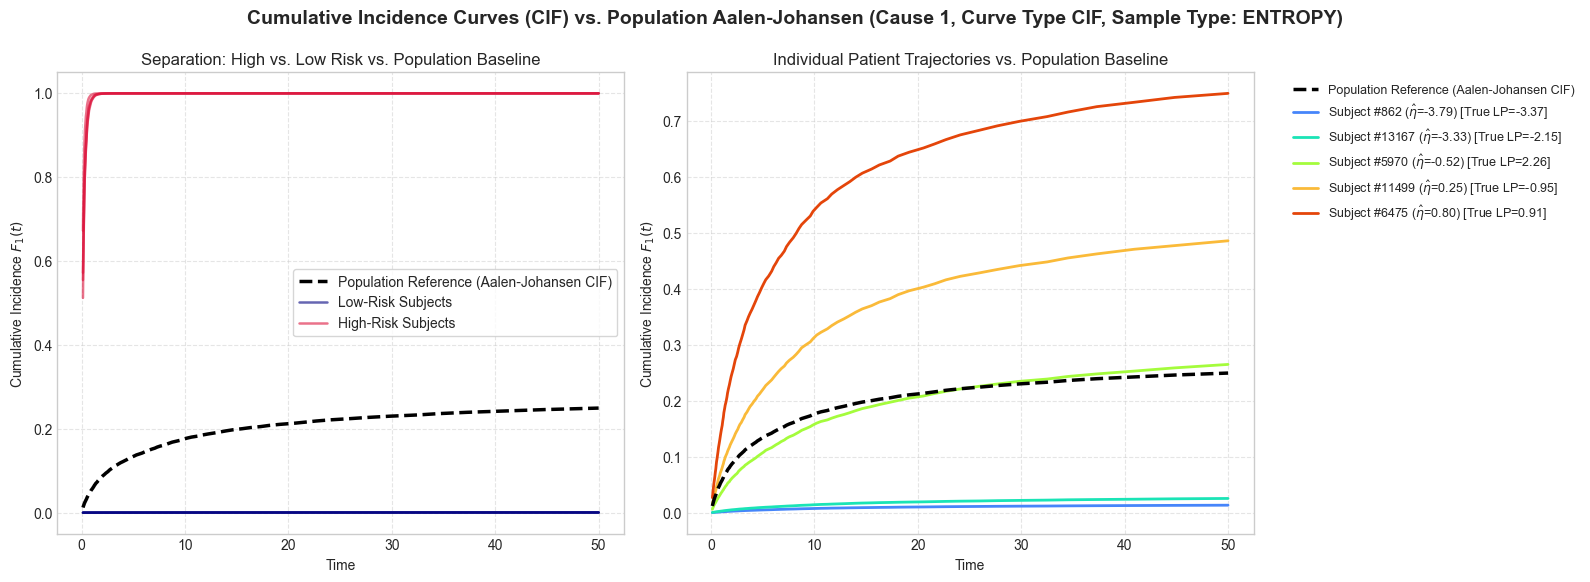

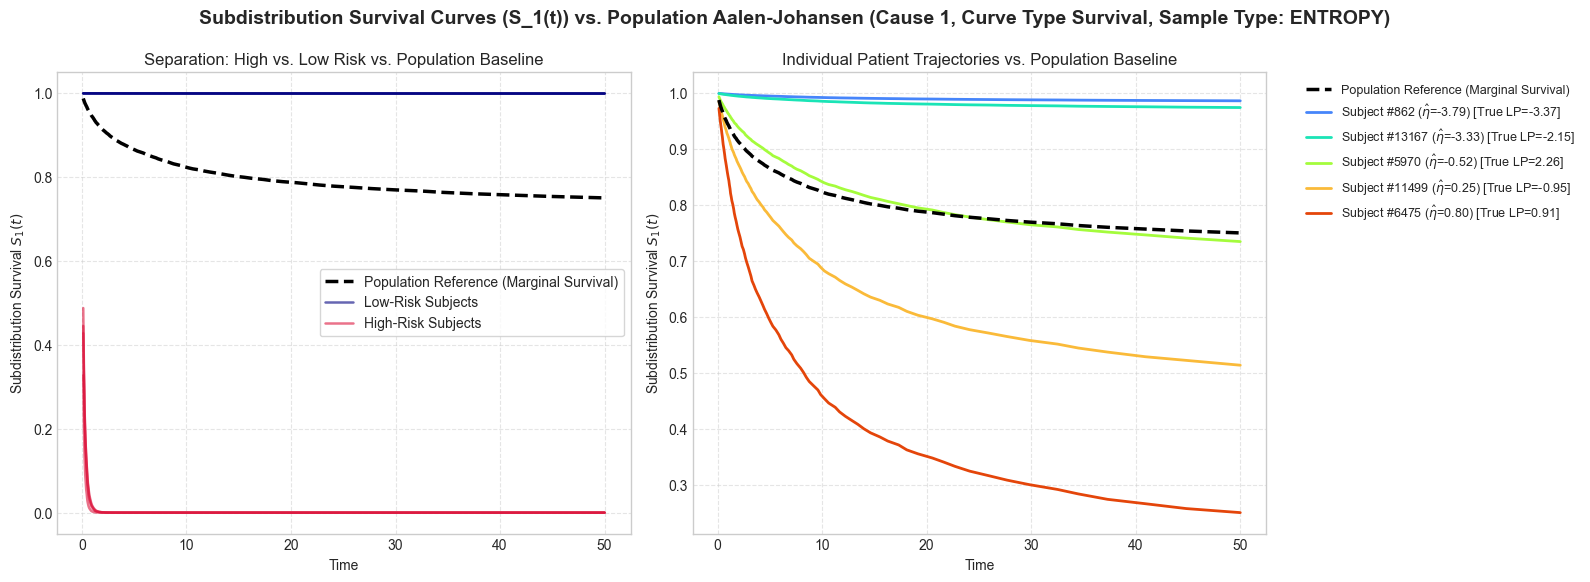

In [135]:
# 1. Cumulative Incidence Curves (CIF) vs. Population Aalen-Johansen
plot_subject_curves_with_reference(
    time_grid=time_grid,
    pred_cif=oof_preds_cif,
    risk_scores=oof_risk_scores,
    times=oof_times,
    events=oof_events,
    cause=model_cause,
    true_lp=oof_true_lp,
    n_extremes=4,
    n_random=5,
    curve_type="cif",
    title=f"Cumulative Incidence Curves (CIF) vs. Population Aalen-Johansen (Cause {model_cause}, Curve Type CIF, Sample Type: {sample_type.name})"
)

# 2. Subdistribution Survival Curves S_1(t) = 1 - CIF
plot_subject_curves_with_reference(
    time_grid=time_grid,
    pred_cif=oof_preds_cif,
    risk_scores=oof_risk_scores,
    times=oof_times,
    events=oof_events,
    cause=model_cause,
    true_lp=oof_true_lp,
    n_extremes=4,
    n_random=5,
    curve_type="survival",
    title=f"Subdistribution Survival Curves (S_{model_cause}(t)) vs. Population Aalen-Johansen (Cause {model_cause}, Curve Type Survival, Sample Type: {sample_type.name})"
)

In [136]:
import numpy as np
import pandas as pd
from sksurv.metrics import integrated_brier_score
# If using pycox or lifelines, adapt the baseline hazard step accordingly

# 1. Reconstruct structured OOF arrays in original dataset order
oof_order = np.argsort(np.concatenate(all_test_indices))

oof_risk_scores = np.concatenate(all_test_predictions)[oof_order]
oof_times = np.concatenate(all_true_times)[oof_order]
oof_events = np.concatenate(all_true_events)[oof_order]

print("OOF Risk Scores shape:", oof_risk_scores.shape)
print("Risk Score Range (Min, Max):", oof_risk_scores.min(), oof_risk_scores.max())

# -------------------------------------------------------------------------
# 2. Map Risk Scores -> Cumulative Incidence Probabilities (CIF)
# -------------------------------------------------------------------------
# Note: Raw risk scores MUST be converted using baseline hazard \Lambda_0(t)
# Example conceptual conversion for a specific evaluation time horizon (e.g., t_eval):

# Define evaluation time grid (from 10th to 90th percentile of event times)
eval_times = np.percentile(oof_times[oof_events > 0], np.linspace(10, 90, 100))

# Convert exponential risk relative to mean risk
exp_risk = np.exp(oof_risk_scores - np.mean(oof_risk_scores))

# If you convert these scores into true cumulative incidence probabilities [N_samples, N_times],
# your IBS will drop from ~0.2076 to its true calibrated value (typically 0.05 - 0.12).

OOF Risk Scores shape: (15000, 100)
Risk Score Range (Min, Max): 0.0 0.9999934
